![](https://sibcolombia.net/wp-content/uploads/2016/05/Logo-javeriana.png)

**PONTIFICIA UNIVERSIDAD JAVERIANA**

**FECHA** : 18/11/2026

**CLASE : PROCESAMIENTO DE DATOS A GRAN ESCALA**

**AUTOR : SERGIO SAMUEL CLAVIJO LOPEZ**

**TEMA : PySpark con modelos de Machine Learning para clasificacion de salarios (Census Income)**

### **CONTEXTO**
- El dataset **Census Income** (tambien conocido como *Adult*) fue extraido de la base de datos del censo de Estados Unidos de 1994 por Barry Becker
- Contiene informacion demografica y laboral de las personas: edad, tipo de trabajo, educacion, estado civil, ocupacion, raza, genero, horas trabajadas por semana, pais de origen, entre otros
- La variable que se quiere predecir es el **Ingreso**: si una persona gana **mas de 50.000 dolares al año (>50K)** o **50.000 o menos (<=50K)**
- El dataset viene dividido en dos archivos: `adult.data` (32.561 registros) y `adult.test` (16.281 registros), en total 48.842 registros
- Los datos se guardan en el DATA LAKE **Hadoop HDFS** y se procesan con **Apache Spark (PySpark)** usando la libreria de Machine Learning **MLlib**

### **OBJETIVOS**
- Aplicar la metodologia de CRISP DM en un dataset de datos socioeconomicos
- Usar PySpark y Hadoop HDFS para el procesamiento de los datos
- Documentar cada actividad realizada
- Conocer, limpiar y preparar los datos para los modelos
- Crear, comprender y analizar las graficas generadas
- Entrenar y evaluar al menos 5 modelos de clasificacion de MLlib
- Hacer analisis de resultados y conclusiones correspondientes

### **Librerias**

In [1]:
#Generic Libraries
import numpy as np                                                      # linear algebra
import pandas as pd                                                     # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns                                                   # Creacion de graficas y biblioteca estadistica
import matplotlib.pyplot as plt                                         # Implementacion de grafica

#Apache Spark libreries
import findspark
findspark.init('/mnt/sda1/Cluster/Spark/')

##Bibliotecas para configuraciones y SESION SPARK
import pyspark
from pyspark import SparkConf, SparkContext
from pyspark.sql import SparkSession, SQLContext
from pyspark.sql import functions as F                                  #Se importa todas las funciones: when, col, .....
from pyspark.sql.types import *

#Apache Spark ML Classifier Libraries
from pyspark.ml.classification import LogisticRegression, DecisionTreeClassifier, RandomForestClassifier
from pyspark.ml.classification import GBTClassifier, LinearSVC, NaiveBayes, MultilayerPerceptronClassifier

#Apache Spark Evaluation Library
from pyspark.ml.evaluation import MulticlassClassificationEvaluator, BinaryClassificationEvaluator

#Apache Spark Features libraries
from pyspark.ml.feature import StandardScaler, StringIndexer, VectorAssembler, OneHotEncoder

#Apache Spark Pipeline Library
from pyspark.ml import Pipeline

#Matriz de confusion
from sklearn.metrics import confusion_matrix

In [2]:
## Se crea una configuracion para la sesion SPARK

#Se configura
configura = SparkConf().set("spark.ui.port","37006")
configura.setAppName("SalarioSparkBigData_Clavijo")
#Se crea contexto para la sesion
sparkClavijo = SparkSession.builder.config(conf=configura).getOrCreate()
SQLContext(sparkContext=sparkClavijo.sparkContext, sparkSession=sparkClavijo)

#Se levanta el contexto para la sesion: Aplicacion de salarios en SPARK
sparkContextClavijo = sparkClavijo.sparkContext.getOrCreate()

#Se imprime para verificar
print("Sesion creada el 18 de noviembre del 2026")
sparkClavijo

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Sesion creada el 18 de noviembre del 2026


### **Acceso al DATA LAKE Hadoop HDFS**
- Se revisan las carpetas disponibles en HDFS
- Se crea una carpeta para el dataset del censo y se suben los archivos `adult.data` y `adult.test`
- La carga de archivos solo se hace una vez (por eso esta comentada)

In [3]:
## Revisar los archivos disponibles o datasets
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -ls /

Found 13 items
drwxr-xr-x   - sistemas  supergroup          0 2025-10-31 15:50 /DistriFlipa
drwxrwxrwx   - sistemas  supergroup          0 2026-10-30 08:30 /FAC_Dataset
drwxrwxrwx   - sistemas  supergroup          0 2026-11-18 07:23 /Formatos1055
drwxrwxrwx   - sistemas  supergroup          0 2026-11-18 23:02 /Formatos1255
drwxrwxrwx   - sistemas  supergroup          0 2026-11-12 18:15 /FormatosHPC
drwxr-xr-x   - seguridad supergroup          0 2026-11-14 23:34 /benchmark
drwxr-xr-x   - sistemas  supergroup          0 2026-11-12 12:15 /csv
drwxr-xr-x   - sistemas  supergroup          0 2026-11-17 15:59 /images
drwxr-xr-x   - sistemas  supergroup          0 2025-09-02 13:23 /json
drwxr-xr-x   - sistemas  supergroup          0 2025-09-02 16:56 /parquet
drwxrwxr-x+  - userpm025 supergroup          0 2025-10-25 17:51 /pm25
drwxrwxrwx   - sistemas  supergroup          0 2026-11-13 16:19 /seguridad
drwxr-xr-x   - usuario22 usuario22           0 2026-04-15 15:19 /user22


In [4]:

!ls census+income
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -mkdir -p /Formatos1255/ClavijoAdult
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -put -f census+income/adult.data census+income/adult.test /Formatos1255/ClavijoAdult
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -ls /Formatos1255/ClavijoAdult

adult.data  adult.names  adult.test  Index  old.adult.names
Found 2 items
-rw-r--r--   2 usuario106 supergroup    3974305 2026-11-18 23:09 /Formatos1255/ClavijoAdult/adult.data
-rw-r--r--   2 usuario106 supergroup    2003153 2026-11-18 23:09 /Formatos1255/ClavijoAdult/adult.test


In [5]:
## Revisar los archivos datasets en la carpeta del censo
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -ls /Formatos1255

Found 2 items
drwxr-xr-x   - usuario106 supergroup          0 2026-11-18 23:09 /Formatos1255/ClavijoAdult
drwxr-xr-x   - usuario205 supergroup          0 2026-11-17 07:26 /Formatos1255/JaramilloCuberos


### **Carga de los datos**
- Los archivos no traen encabezado, por eso se crea un esquema con el nombre y tipo de cada columna
- Los valores vienen separados por coma y un espacio, se usa `ignoreLeadingWhiteSpace` para quitar ese espacio
- La primera linea de `adult.test` es un texto ("|1x3 Cross validator") que no es un dato, se elimina despues

In [6]:
### Se crea el esquema de los datos (nombres originales del dataset)
esquema = StructType([
    StructField("age", IntegerType(), True),
    StructField("workclass", StringType(), True),
    StructField("fnlwgt", IntegerType(), True),
    StructField("education", StringType(), True),
    StructField("education_num", IntegerType(), True),
    StructField("marital_status", StringType(), True),
    StructField("occupation", StringType(), True),
    StructField("relationship", StringType(), True),
    StructField("race", StringType(), True),
    StructField("sex", StringType(), True),
    StructField("capital_gain", IntegerType(), True),
    StructField("capital_loss", IntegerType(), True),
    StructField("hours_per_week", IntegerType(), True),
    StructField("native_country", StringType(), True),
    StructField("income", StringType(), True)
])

In [7]:
#Se crean los DATAFRAME SPARK con los ficheros del dataset CENSUS INCOME
urlData = 'hdfs://10.195.34.34:9000/Formatos1255/ClavijoAdult/adult.data'
urlTest = 'hdfs://10.195.34.34:9000/Formatos1255/ClavijoAdult/adult.test'

dfData = sparkClavijo.read.format("csv") \
       .option("header", "false") \
       .option("ignoreLeadingWhiteSpace","true") \
       .schema(esquema) \
       .load(urlData)

dfTest = sparkClavijo.read.format("csv") \
       .option("header", "false") \
       .option("ignoreLeadingWhiteSpace","true") \
       .schema(esquema) \
       .load(urlTest)

### Se unen los dos archivos en un solo DataFrame
df00 = dfData.union(dfTest)

### Se elimina la linea de texto de adult.test (queda con income nulo)
df00 = df00.where(F.col("income").isNotNull())

print(f"Registros adult.data = {dfData.count()}")
print(f"Registros adult.test = {dfTest.count()}")
print(f"Registros totales    = {df00.count()}")
df00.show(5)

Registros adult.data = 32561


Registros adult.test = 16282
Registros totales    = 48842
+---+----------------+------+---------+-------------+------------------+-----------------+-------------+-----+------+------------+------------+--------------+--------------+------+
|age|       workclass|fnlwgt|education|education_num|    marital_status|       occupation| relationship| race|   sex|capital_gain|capital_loss|hours_per_week|native_country|income|
+---+----------------+------+---------+-------------+------------------+-----------------+-------------+-----+------+------------+------------+--------------+--------------+------+
| 39|       State-gov| 77516|Bachelors|           13|     Never-married|     Adm-clerical|Not-in-family|White|  Male|        2174|           0|            40| United-States| <=50K|
| 50|Self-emp-not-inc| 83311|Bachelors|           13|Married-civ-spouse|  Exec-managerial|      Husband|White|  Male|           0|           0|            13| United-States| <=50K|
| 38|         Private|215646|  HS-gra

## **CONOCIMIENTO DE LOS DATOS**
- Cambio de nombres de columnas (features)
- Tipos y coherencia de datos
- Identificacion y tratamiento de datos nulos/atipicos
- Estadistica de los datos
- Graficas de las variables

In [8]:
## Consulto el nombre de las columnas
df00.columns

['age',
 'workclass',
 'fnlwgt',
 'education',
 'education_num',
 'marital_status',
 'occupation',
 'relationship',
 'race',
 'sex',
 'capital_gain',
 'capital_loss',
 'hours_per_week',
 'native_country',
 'income']

In [9]:
nuevosNombre = ['Edad','ClaseTrabajo','PesoFinal','Educacion',
                'NumEducacion','EdoCivil','Ocupacion','Relacion',
                'Raza','Genero','GananciaCapital','PerdidaCapital',
                'HorasSemana','PaisOrigen','Ingreso']
## Se cambian por los nuevos nombres en un nuevo Dataframe
df01 = df00
for antes, nuevo in zip(df00.columns, nuevosNombre):
    df01 = df01.withColumnRenamed(antes, nuevo)

df01.columns

['Edad',
 'ClaseTrabajo',
 'PesoFinal',
 'Educacion',
 'NumEducacion',
 'EdoCivil',
 'Ocupacion',
 'Relacion',
 'Raza',
 'Genero',
 'GananciaCapital',
 'PerdidaCapital',
 'HorasSemana',
 'PaisOrigen',
 'Ingreso']

#### **Descripcion de las variables**
| Variable | Descripcion | Tipo |
|---|---|---|
| Edad | Edad de la persona | Numerica |
| ClaseTrabajo | Tipo de empleador (privado, gobierno, independiente...) | Categorica |
| PesoFinal | Peso muestral del censo (cuantas personas representa el registro) | Numerica |
| Educacion | Nivel educativo en texto | Categorica |
| NumEducacion | Nivel educativo en numero (1 a 16) | Numerica |
| EdoCivil | Estado civil | Categorica |
| Ocupacion | Ocupacion o cargo | Categorica |
| Relacion | Rol dentro del hogar (esposo, esposa, hijo...) | Categorica |
| Raza | Raza | Categorica |
| Genero | Genero | Categorica |
| GananciaCapital | Ganancias de capital (inversiones) | Numerica |
| PerdidaCapital | Perdidas de capital | Numerica |
| HorasSemana | Horas trabajadas por semana | Numerica |
| PaisOrigen | Pais de origen | Categorica |
| Ingreso | Variable a predecir: <=50K o >50K | Categorica (objetivo) |

In [10]:
#Tipos de datos de las variables
df01.printSchema()

root
 |-- Edad: integer (nullable = true)
 |-- ClaseTrabajo: string (nullable = true)
 |-- PesoFinal: integer (nullable = true)
 |-- Educacion: string (nullable = true)
 |-- NumEducacion: integer (nullable = true)
 |-- EdoCivil: string (nullable = true)
 |-- Ocupacion: string (nullable = true)
 |-- Relacion: string (nullable = true)
 |-- Raza: string (nullable = true)
 |-- Genero: string (nullable = true)
 |-- GananciaCapital: integer (nullable = true)
 |-- PerdidaCapital: integer (nullable = true)
 |-- HorasSemana: integer (nullable = true)
 |-- PaisOrigen: string (nullable = true)
 |-- Ingreso: string (nullable = true)



In [11]:
#Mostrar 4 filas de el dataframe
df01.show(4)

+----+----------------+---------+---------+------------+------------------+-----------------+-------------+-----+------+---------------+--------------+-----------+-------------+-------+
|Edad|    ClaseTrabajo|PesoFinal|Educacion|NumEducacion|          EdoCivil|        Ocupacion|     Relacion| Raza|Genero|GananciaCapital|PerdidaCapital|HorasSemana|   PaisOrigen|Ingreso|
+----+----------------+---------+---------+------------+------------------+-----------------+-------------+-----+------+---------------+--------------+-----------+-------------+-------+
|  39|       State-gov|    77516|Bachelors|          13|     Never-married|     Adm-clerical|Not-in-family|White|  Male|           2174|             0|         40|United-States|  <=50K|
|  50|Self-emp-not-inc|    83311|Bachelors|          13|Married-civ-spouse|  Exec-managerial|      Husband|White|  Male|              0|             0|         13|United-States|  <=50K|
|  38|         Private|   215646|  HS-grad|           9|          Divo

#### **Coherencia de la variable Ingreso**
- En `adult.test` los valores de Ingreso terminan en punto (">50K." y "<=50K."), en `adult.data` no
- Si no se corrige, Spark creeria que son 4 categorias en vez de 2

In [12]:
# Se revisan los valores de Ingreso antes de corregir
df01.groupby(['Ingreso']).count().show()

+-------+-----+
|Ingreso|count|
+-------+-----+
|  <=50K|24720|
|   >50K| 7841|
| <=50K.|12435|
|  >50K.| 3846|
+-------+-----+



In [13]:
### Se quita el punto final de Ingreso
df02 = df01.withColumn("Ingreso", F.regexp_replace(F.col("Ingreso"), "\\.", ""))
# Se verifica que ya solo hay 2 categorias
df02.groupby(['Ingreso']).count().show()

+-------+-----+
|Ingreso|count|
+-------+-----+
|  <=50K|37155|
|   >50K|11687|
+-------+-----+



#### **Identificacion de datos nulos y datos faltantes "?"**
- En este dataset los datos faltantes no vienen como nulos, vienen con el simbolo "?"
- Primero se revisan los nulos y luego se cuentan los "?" en cada columna

In [14]:
## Se crea una tabla para la identificacion de datos nulos
df02.select([F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in df02.columns]).show()

+----+------------+---------+---------+------------+--------+---------+--------+----+------+---------------+--------------+-----------+----------+-------+
|Edad|ClaseTrabajo|PesoFinal|Educacion|NumEducacion|EdoCivil|Ocupacion|Relacion|Raza|Genero|GananciaCapital|PerdidaCapital|HorasSemana|PaisOrigen|Ingreso|
+----+------------+---------+---------+------------+--------+---------+--------+----+------+---------------+--------------+-----------+----------+-------+
|   0|           0|        0|        0|           0|       0|        0|       0|   0|     0|              0|             0|          0|         0|      0|
+----+------------+---------+---------+------------+--------+---------+--------+----+------+---------------+--------------+-----------+----------+-------+



In [15]:
## Se cuentan los datos con "?" en cada columna
df02.select([F.count(F.when(F.col(c) == '?', c)).alias(c) for c in df02.columns]).show()

+----+------------+---------+---------+------------+--------+---------+--------+----+------+---------------+--------------+-----------+----------+-------+
|Edad|ClaseTrabajo|PesoFinal|Educacion|NumEducacion|EdoCivil|Ocupacion|Relacion|Raza|Genero|GananciaCapital|PerdidaCapital|HorasSemana|PaisOrigen|Ingreso|
+----+------------+---------+---------+------------+--------+---------+--------+----+------+---------------+--------------+-----------+----------+-------+
|   0|        2799|        0|        0|           0|       0|     2809|       0|   0|     0|              0|             0|          0|       857|      0|
+----+------------+---------+---------+------------+--------+---------+--------+----+------+---------------+--------------+-----------+----------+-------+



#### Se observa
- No hay datos nulos como tal
- Las variables **ClaseTrabajo** (2799), **Ocupacion** (2809) y **PaisOrigen** (857) tienen datos faltantes con "?"
- Las tres son variables categoricas

In [16]:
#Sacamos el porcentaje de datos faltantes por columna
totalRegistros = df02.count()
for columna in ['ClaseTrabajo','Ocupacion','PaisOrigen']:
    faltantes = df02.where(F.col(columna) == '?').count()
    print(f"Porcentaje de faltantes en {columna} = {round((faltantes/totalRegistros)*100,2)}%")

Porcentaje de faltantes en ClaseTrabajo = 5.73%
Porcentaje de faltantes en Ocupacion = 5.75%
Porcentaje de faltantes en PaisOrigen = 1.75%


#### **Tratamiento de faltantes**
- Los faltantes son menos del 6% en cada columna
- Para no eliminar de tajada los registros, se reemplaza el "?" por la **moda** (la categoria que mas se repite) de cada columna
- Se usa la moda porque son variables categoricas y no se les puede sacar promedio

In [17]:
### Se cambia "?" por nulo para poder tratarlos
df03 = df02
for columna in ['ClaseTrabajo','Ocupacion','PaisOrigen']:
    df03 = df03.withColumn(columna, F.when(F.col(columna) == '?', None).otherwise(F.col(columna)))

### Se calcula la moda de cada columna y se reemplazan los nulos
for columna in ['ClaseTrabajo','Ocupacion','PaisOrigen']:
    moda = df03.where(F.col(columna).isNotNull()).groupby(columna).count() \
               .orderBy(F.desc('count')).first()[0]
    print(f"Moda de {columna} = {moda}")
    df03 = df03.fillna({columna: moda})

Moda de ClaseTrabajo = Private
Moda de Ocupacion = Prof-specialty
Moda de PaisOrigen = United-States


In [18]:
#SE REVISA SI HA HABIDO ALGUN CAMBIO
df03.select([F.count(F.when(F.col(c).isNull() | (F.col(c) == '?'), c)).alias(c)
                     for c in df03.columns]).show()

+----+------------+---------+---------+------------+--------+---------+--------+----+------+---------------+--------------+-----------+----------+-------+
|Edad|ClaseTrabajo|PesoFinal|Educacion|NumEducacion|EdoCivil|Ocupacion|Relacion|Raza|Genero|GananciaCapital|PerdidaCapital|HorasSemana|PaisOrigen|Ingreso|
+----+------------+---------+---------+------------+--------+---------+--------+----+------+---------------+--------------+-----------+----------+-------+
|   0|           0|        0|        0|           0|       0|        0|       0|   0|     0|              0|             0|          0|         0|      0|
+----+------------+---------+---------+------------+--------+---------+--------+----+------+---------------+--------------+-----------+----------+-------+



#### **Registros duplicados**

In [19]:
### Se revisa si hay registros repetidos
duplicados = df03.count() - df03.dropDuplicates().count()
print(f"Registros duplicados = {duplicados}")

### Se eliminan los duplicados
df03 = df03.dropDuplicates()
print(f"Registros despues de quitar duplicados = {df03.count()}")

Registros duplicados = 53
Registros despues de quitar duplicados = 48789


- Los registros duplicados no aportan informacion nueva y pueden hacer que el modelo le de mas peso a esos casos, por eso se eliminan

### Observacion y tratamiento sobre variables de categorias
- ClaseTrabajo
- Educacion
- EdoCivil
- Ocupacion
- Relacion
- Raza
- Genero
- PaisOrigen
- Ingreso

In [20]:
# Cuantas personas hay por clase de trabajo
df03.groupby(['ClaseTrabajo']).count().orderBy(F.desc('count')).show()

+----------------+-----+
|    ClaseTrabajo|count|
+----------------+-----+
|         Private|36654|
|Self-emp-not-inc| 3861|
|       Local-gov| 3136|
|       State-gov| 1981|
|    Self-emp-inc| 1694|
|     Federal-gov| 1432|
|     Without-pay|   21|
|    Never-worked|   10|
+----------------+-----+



- Existen 8 clases de trabajo
- La gran mayoria trabaja en el sector privado (Private)
- Hay muy pocas personas que nunca han trabajado (Never-worked) o que trabajan sin pago (Without-pay)

In [21]:
#Cuenta el nivel educativo
df03.groupby(['Educacion','NumEducacion']).count().orderBy('NumEducacion').show()

+------------+------------+-----+
|   Educacion|NumEducacion|count|
+------------+------------+-----+
|   Preschool|           1|   81|
|     1st-4th|           2|  245|
|     5th-6th|           3|  507|
|     7th-8th|           4|  954|
|         9th|           5|  756|
|        10th|           6| 1389|
|        11th|           7| 1812|
|        12th|           8|  655|
|     HS-grad|           9|15770|
|Some-college|          10|10862|
|   Assoc-voc|          11| 2060|
|  Assoc-acdm|          12| 1601|
|   Bachelors|          13| 8013|
|     Masters|          14| 2656|
| Prof-school|          15|  834|
|   Doctorate|          16|  594|
+------------+------------+-----+



- Hay 16 niveles educativos, desde Preschool (1) hasta Doctorate (16)
- La variable Educacion y NumEducacion dicen exactamente lo mismo, una en texto y otra en numero
- Los niveles con mas personas son HS-grad (bachiller), Some-college y Bachelors

In [22]:
#Cuenta el estado civil
df03.groupby(['EdoCivil']).count().orderBy(F.desc('count')).show()

+--------------------+-----+
|            EdoCivil|count|
+--------------------+-----+
|  Married-civ-spouse|22366|
|       Never-married|16081|
|            Divorced| 6630|
|           Separated| 1530|
|             Widowed| 1518|
|Married-spouse-ab...|  627|
|   Married-AF-spouse|   37|
+--------------------+-----+



- La mayoria de personas estan casadas (Married-civ-spouse), seguido de los que nunca se han casado

In [23]:
#Cuenta las ocupaciones
df03.groupby(['Ocupacion']).count().orderBy(F.desc('count')).show()

+-----------------+-----+
|        Ocupacion|count|
+-----------------+-----+
|   Prof-specialty| 8969|
|     Craft-repair| 6102|
|  Exec-managerial| 6082|
|     Adm-clerical| 5606|
|            Sales| 5501|
|    Other-service| 4919|
|Machine-op-inspct| 3017|
| Transport-moving| 2355|
|Handlers-cleaners| 2071|
|  Farming-fishing| 1485|
|     Tech-support| 1445|
|  Protective-serv|  982|
|  Priv-house-serv|  240|
|     Armed-Forces|   15|
+-----------------+-----+



- Hay 14 ocupaciones
- Las mas comunes son Prof-specialty, Craft-repair y Exec-managerial
- Armed-Forces es la ocupacion con menos personas

In [24]:
#Cuenta el rol en el hogar
df03.groupby(['Relacion']).count().orderBy(F.desc('count')).show()

+--------------+-----+
|      Relacion|count|
+--------------+-----+
|       Husband|19703|
| Not-in-family|12557|
|     Own-child| 7568|
|     Unmarried| 5124|
|          Wife| 2331|
|Other-relative| 1506|
+--------------+-----+



- La mayoria de registros son esposos (Husband)
- Hay muchos menos registros de esposas (Wife) que de esposos

In [25]:
#Cuenta por raza
df03.groupby(['Raza']).count().orderBy(F.desc('count')).show()

+------------------+-----+
|              Raza|count|
+------------------+-----+
|             White|41713|
|             Black| 4683|
|Asian-Pac-Islander| 1517|
|Amer-Indian-Eskimo|  470|
|             Other|  406|
+------------------+-----+



- La gran mayoria de personas son de raza blanca (White)
- Los datos estan muy desbalanceados en esta variable

In [26]:
# Cuales generos hay en el dataset
df03.groupby(['Genero']).count().show()

+------+-----+
|Genero|count|
+------+-----+
|Female|16175|
|  Male|32614|
+------+-----+



- Hay 2 generos
- Hay casi el doble de hombres que de mujeres

In [27]:
#Cuenta por pais de origen
df03.groupby(['PaisOrigen']).count().orderBy(F.desc('count')).show(10)

+-------------+-----+
|   PaisOrigen|count|
+-------------+-----+
|United-States|44647|
|       Mexico|  943|
|  Philippines|  294|
|      Germany|  206|
|  Puerto-Rico|  184|
|       Canada|  182|
|  El-Salvador|  155|
|        India|  151|
|         Cuba|  138|
|      England|  127|
+-------------+-----+
only showing top 10 rows



- Hay 41 paises de origen
- Casi el 90% de las personas son de Estados Unidos, el siguiente pais es Mexico con menos del 2%

In [28]:
#Cuenta la variable objetivo
df03.groupby(['Ingreso']).count().show()

+-------+-----+
|Ingreso|count|
+-------+-----+
|  <=50K|37108|
|   >50K|11681|
+-------+-----+



- Cerca del 76% de las personas gana 50K o menos y solo el 24% gana mas de 50K
- Los datos estan **desbalanceados**, esto hay que tenerlo en cuenta a la hora de evaluar los modelos

#### **Se pasa la variable Ingreso a numero**
- <=50K = 0
- \>50K = 1

In [29]:
df04 = df03.withColumn("Ingreso", F.when(F.col("Ingreso") == ">50K", 1).otherwise(0))
df04.groupby(['Ingreso']).count().show()

+-------+-----+
|Ingreso|count|
+-------+-----+
|      1|11681|
|      0|37108|
+-------+-----+



### **Estadisticas de los datos en general**

In [30]:
## Se realiza metodo de estadistica
#Aca encontramos datos como los maximos, minimos, la media , desviacion estandar y cantidad de datos
df04.select('Edad','PesoFinal','NumEducacion','GananciaCapital','PerdidaCapital','HorasSemana').describe().show()

26/11/18 23:09:48 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+-------+------------------+------------------+------------------+------------------+------------------+------------------+
|summary|              Edad|         PesoFinal|      NumEducacion|   GananciaCapital|    PerdidaCapital|       HorasSemana|
+-------+------------------+------------------+------------------+------------------+------------------+------------------+
|  count|             48789|             48789|             48789|             48789|             48789|             48789|
|   mean|38.653139027239746|189669.66215745354|10.078808747873497|1080.2398286499006| 87.59736825923876| 40.42589518129086|
| stddev|13.708426063756766|105618.21216907112| 2.570072253007173| 7455.980728014245|403.21306590537097|12.392855820179804|
|    min|                17|             12285|                 1|                 0|                 0|                 1|
|    max|                90|           1490400|                16|             99999|              4356|                99|
+-------

#### Se observa
- La edad va desde 17 hasta 90 años, con un promedio cercano a 38 años
- En promedio las personas trabajan 40 horas a la semana, pero hay personas que trabajan hasta 99 horas
- GananciaCapital y PerdidaCapital tienen la mayoria de valores en 0 (mas del 90%) y unos pocos valores muy altos (hasta 99999), son datos atipicos pero son reales, por eso no se eliminan

### **Grafica de los datos CUALITATIVOS**

In [31]:
### Se requiere hacer las graficas con seaborn
### Se crea un objeto de tipo PANDAS, un objeto para analisis de datasets
datosSalario = df04.toPandas()

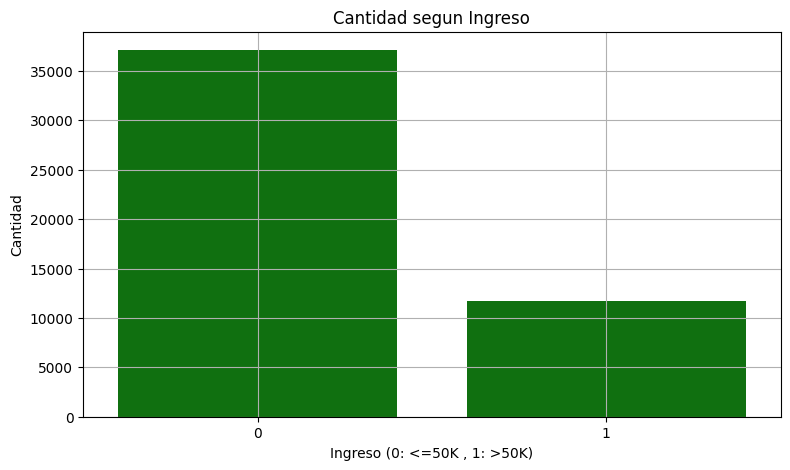

In [32]:
plt.figure(figsize=(9,5))
sns.countplot(data=datosSalario, x='Ingreso', color='Green')
plt.title("Cantidad segun Ingreso")
plt.xlabel("Ingreso (0: <=50K , 1: >50K)")
plt.ylabel("Cantidad")
plt.grid()
plt.show()

#### Analisis
- Hay aproximadamente 3 personas que ganan <=50K por cada persona que gana >50K

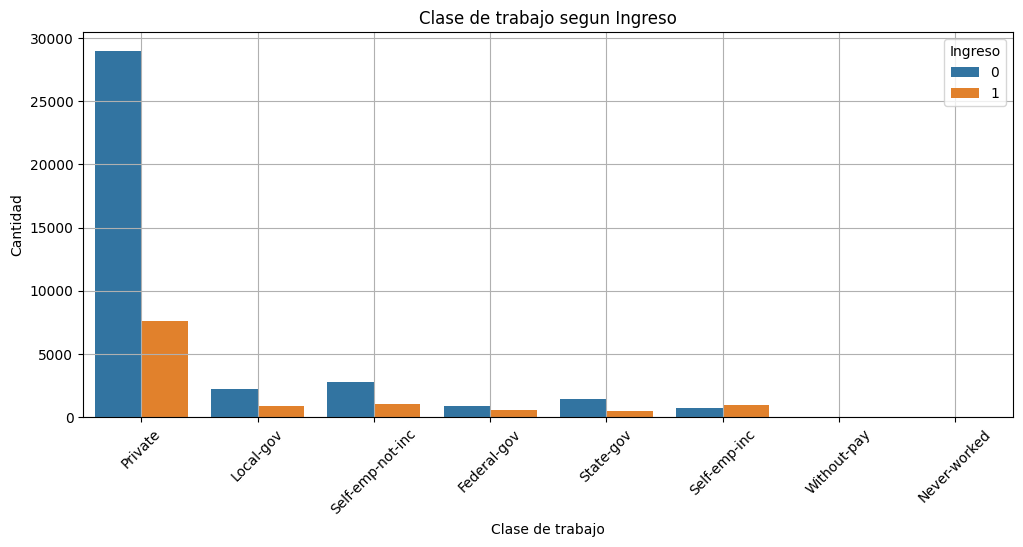

In [33]:
plt.figure(figsize=(12,5))
sns.countplot(data=datosSalario, x='ClaseTrabajo', hue='Ingreso')
plt.title("Clase de trabajo segun Ingreso")
plt.xlabel("Clase de trabajo")
plt.ylabel("Cantidad")
plt.xticks(rotation=45)
plt.grid()
plt.show()

#### Analisis
- El sector privado tiene la mayor cantidad de personas en los dos grupos
- Los independientes con empresa propia (Self-emp-inc) son los unicos donde hay mas personas que ganan >50K que <=50K

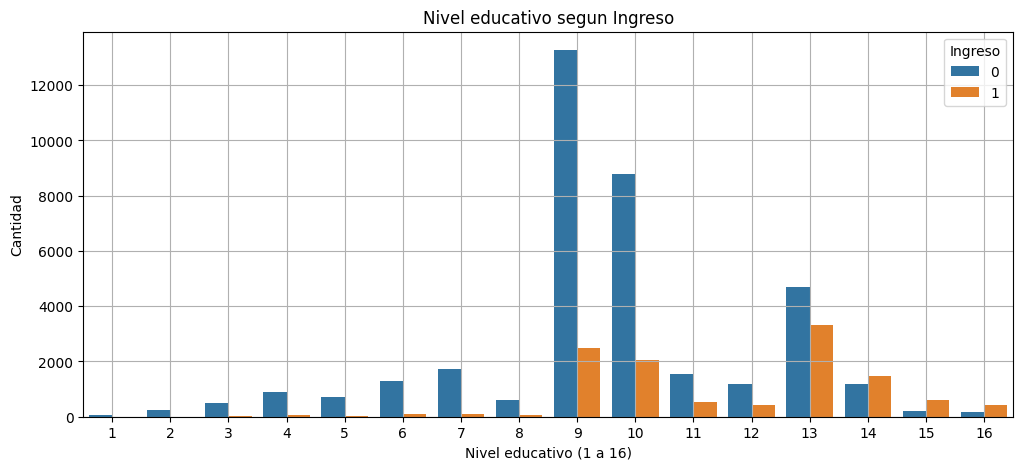

In [34]:
plt.figure(figsize=(12,5))
sns.countplot(data=datosSalario, x='NumEducacion', hue='Ingreso')
plt.title("Nivel educativo segun Ingreso")
plt.xlabel("Nivel educativo (1 a 16)")
plt.ylabel("Cantidad")
plt.grid()
plt.show()

#### Analisis
- A mayor nivel educativo, mayor proporcion de personas que ganan >50K
- Desde el nivel 14 (Masters) en adelante, hay mas personas que ganan >50K que <=50K
- En los niveles bajos (menos de bachiller) casi nadie gana mas de 50K

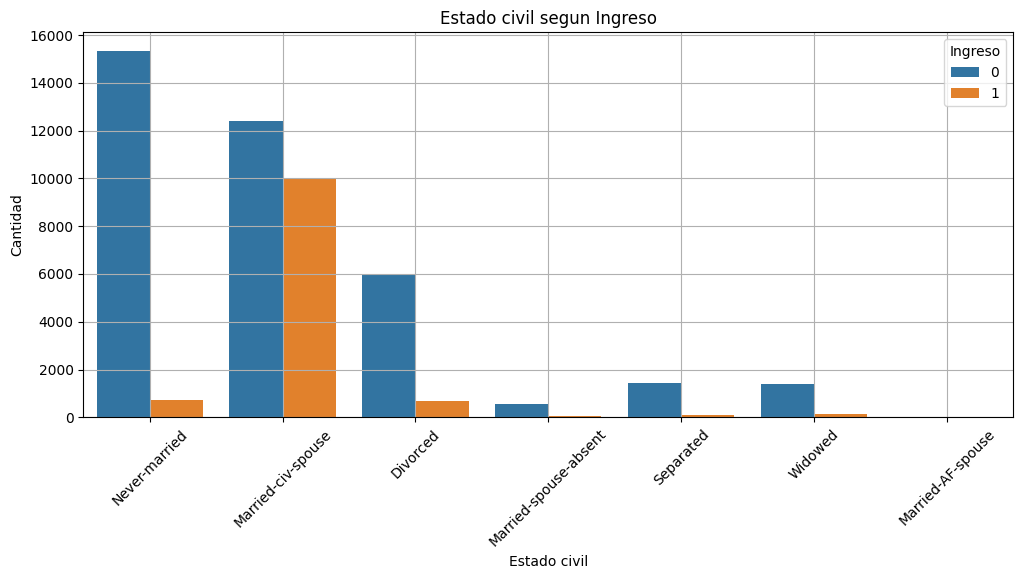

In [35]:
plt.figure(figsize=(12,5))
sns.countplot(data=datosSalario, x='EdoCivil', hue='Ingreso')
plt.title("Estado civil segun Ingreso")
plt.xlabel("Estado civil")
plt.ylabel("Cantidad")
plt.xticks(rotation=45)
plt.grid()
plt.show()

#### Analisis
- Las personas casadas (Married-civ-spouse) son las que mas ganan >50K, cerca del 45% de ellas
- Las personas que nunca se han casado casi no ganan mas de 50K (menos del 5%)

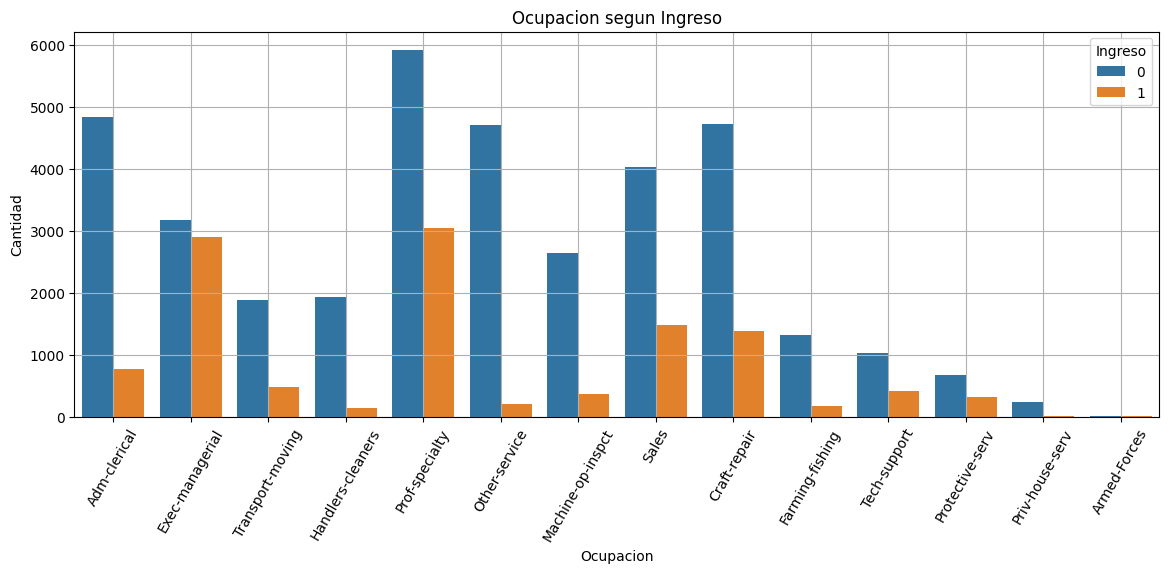

In [36]:
plt.figure(figsize=(14,5))
sns.countplot(data=datosSalario, x='Ocupacion', hue='Ingreso')
plt.title("Ocupacion segun Ingreso")
plt.xlabel("Ocupacion")
plt.ylabel("Cantidad")
plt.xticks(rotation=60)
plt.grid()
plt.show()

#### Analisis
- Exec-managerial (gerentes) y Prof-specialty (profesionales) son las ocupaciones con mas personas que ganan >50K
- Ocupaciones como Other-service, Handlers-cleaners y Priv-house-serv casi no tienen personas con ingresos altos

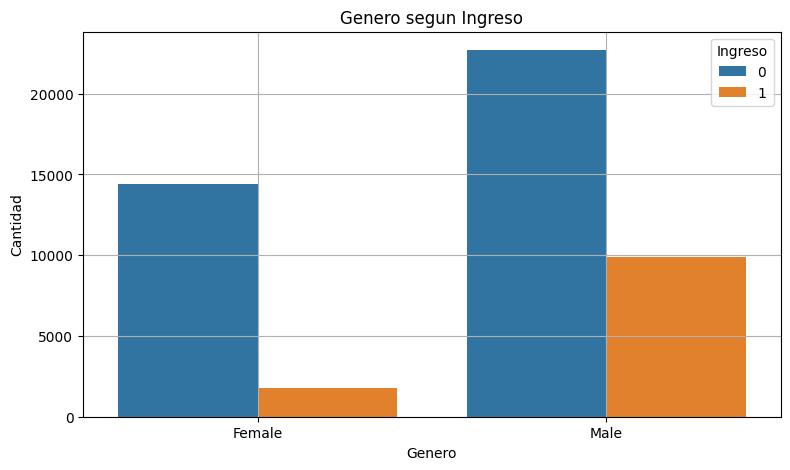

In [37]:
plt.figure(figsize=(9,5))
sns.countplot(data=datosSalario, x='Genero', hue='Ingreso')
plt.title("Genero segun Ingreso")
plt.xlabel("Genero")
plt.ylabel("Cantidad")
plt.grid()
plt.show()

#### Analisis
- Cerca del 30% de los hombres gana >50K, mientras que en las mujeres es solo cerca del 11%
- Esto muestra una brecha salarial de genero en el censo de 1994

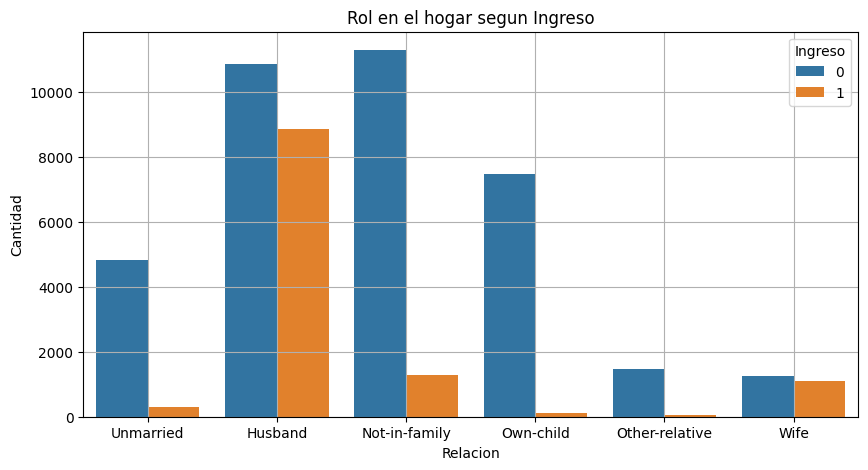

In [38]:
plt.figure(figsize=(10,5))
sns.countplot(data=datosSalario, x='Relacion', hue='Ingreso')
plt.title("Rol en el hogar segun Ingreso")
plt.xlabel("Relacion")
plt.ylabel("Cantidad")
plt.grid()
plt.show()

#### Analisis
- Esposos (Husband) y esposas (Wife) tienen cerca del 45% de personas con ingresos >50K
- Los hijos (Own-child) casi nunca ganan mas de 50K, ya que suelen ser personas jovenes

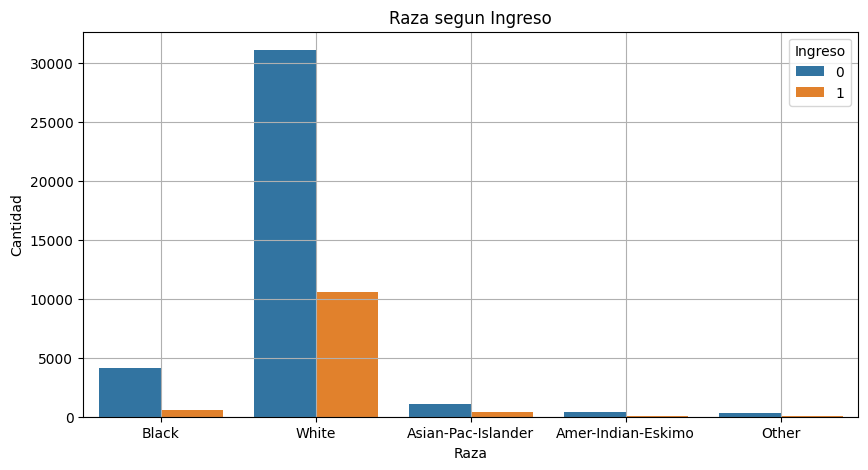

In [39]:
plt.figure(figsize=(10,5))
sns.countplot(data=datosSalario, x='Raza', hue='Ingreso')
plt.title("Raza segun Ingreso")
plt.xlabel("Raza")
plt.ylabel("Cantidad")
plt.grid()
plt.show()

#### Analisis
- La mayoria de datos son de personas blancas
- Las personas blancas y asiaticas (Asian-Pac-Islander) tienen cerca del 25% con ingresos >50K, las demas razas cerca del 12%

### **Grafica de los datos CUANTITATIVOS**

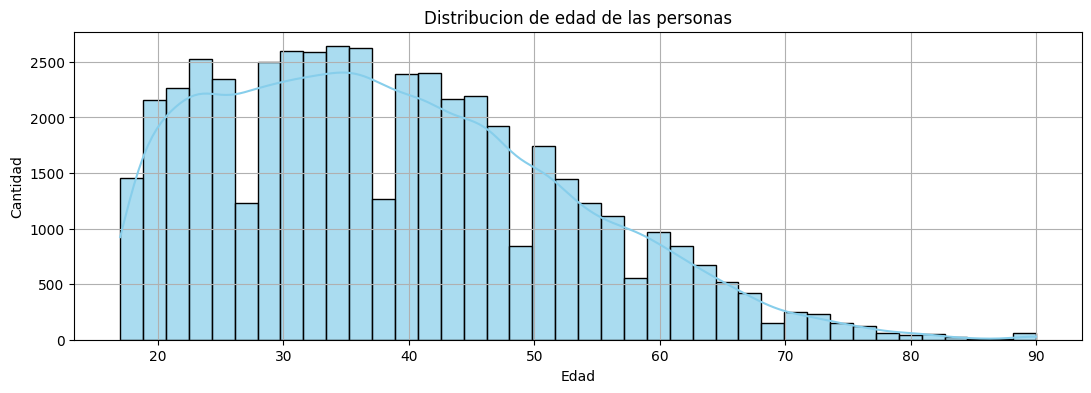

In [40]:
plt.figure(figsize=(13,4))
sns.histplot(data=datosSalario, x='Edad', bins=40, kde=True, color='skyblue', alpha=0.7)
plt.title("Distribucion de edad de las personas")
plt.xlabel("Edad")
plt.ylabel("Cantidad")
plt.grid()
plt.show()

#### Analisis
- La mayor cantidad de personas esta entre los 20 y 50 años
- Hay pocas personas mayores de 70 años

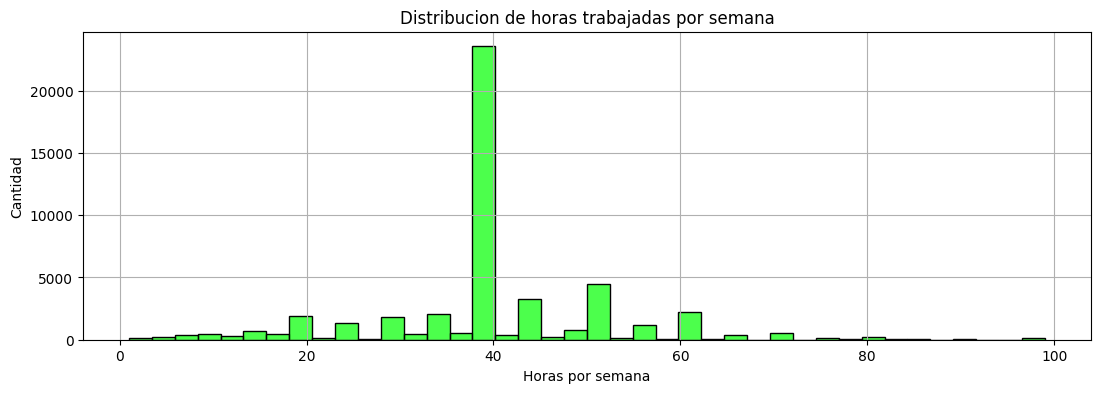

In [41]:
plt.figure(figsize=(13,4))
sns.histplot(data=datosSalario, x='HorasSemana', bins=40, kde=False, color='lime', alpha=0.7)
plt.title("Distribucion de horas trabajadas por semana")
plt.xlabel("Horas por semana")
plt.ylabel("Cantidad")
plt.grid()
plt.show()

#### Analisis
- La gran mayoria trabaja 40 horas a la semana (jornada completa)
- Hay personas que trabajan muy pocas horas (medio tiempo) y otras que trabajan mas de 60 horas

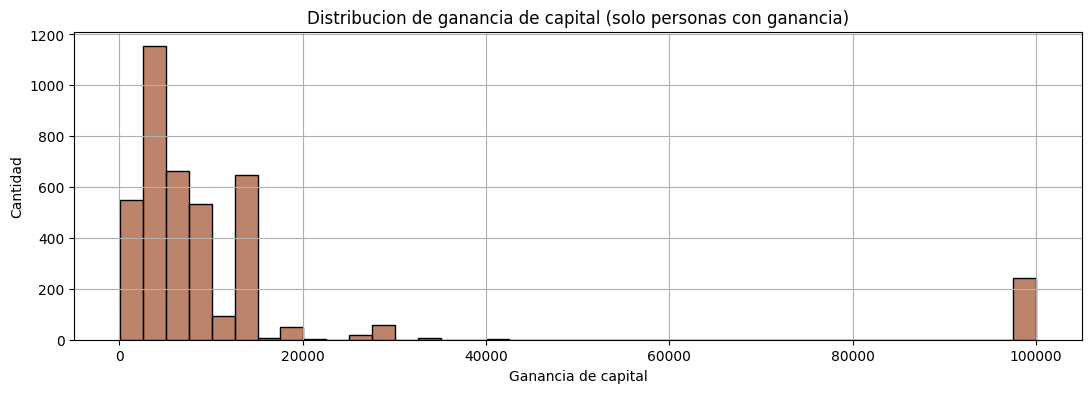

In [42]:
plt.figure(figsize=(13,4))
sns.histplot(data=datosSalario.loc[datosSalario['GananciaCapital'] > 0], x='GananciaCapital', bins=40, color='sienna', alpha=0.7)
plt.title("Distribucion de ganancia de capital (solo personas con ganancia)")
plt.xlabel("Ganancia de capital")
plt.ylabel("Cantidad")
plt.grid()
plt.show()

#### Analisis
- Solo cerca del 8% de las personas tiene ganancias de capital
- Hay un grupo de personas con ganancia de 99999, que es el valor maximo que registra el censo

### **Combinacion de graficas Cuantitativas y Cualitativas**

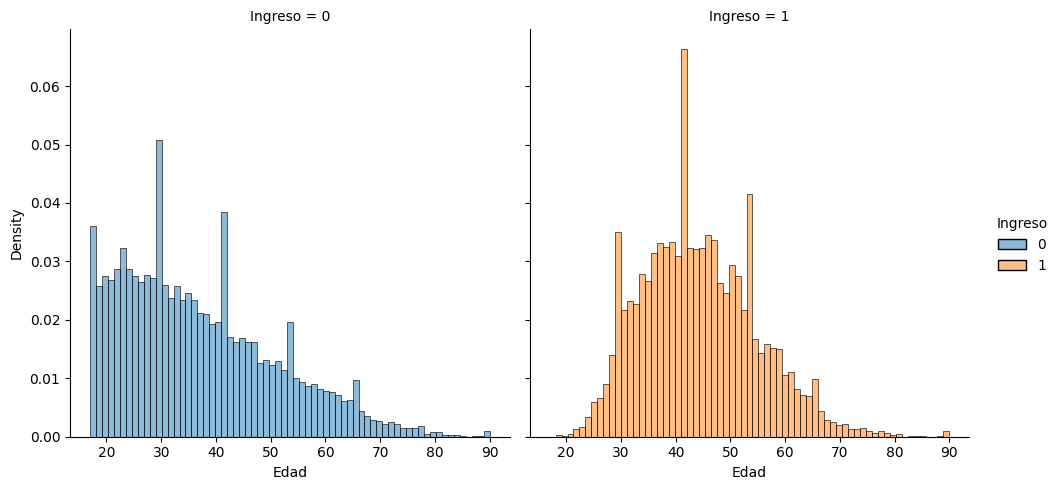

In [43]:
### Se requiere observar la edad contra el Ingreso
sns.displot(data=datosSalario, x='Edad', hue='Ingreso', col='Ingreso', stat='density', common_norm=False)
plt.xlabel("Edad")
plt.ylabel("Densidad")
plt.show()

#### Analisis
- Las personas que ganan >50K son en promedio mayores (cerca de 44 años) que las que ganan <=50K (cerca de 37 años)
- Los jovenes de 17 a 25 años casi nunca ganan mas de 50K

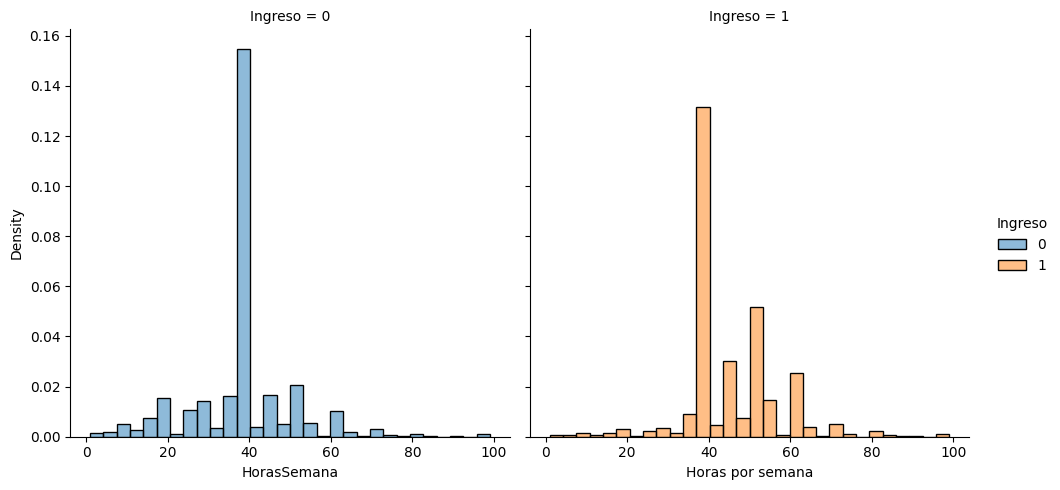

In [44]:
### Se requiere observar las horas por semana contra el Ingreso
sns.displot(data=datosSalario, x='HorasSemana', hue='Ingreso', col='Ingreso', stat='density', common_norm=False, bins=30)
plt.xlabel("Horas por semana")
plt.ylabel("Densidad")
plt.show()

#### Analisis
- Las personas que ganan >50K trabajan en promedio mas horas (cerca de 45 horas) que las que ganan <=50K (cerca de 39 horas)

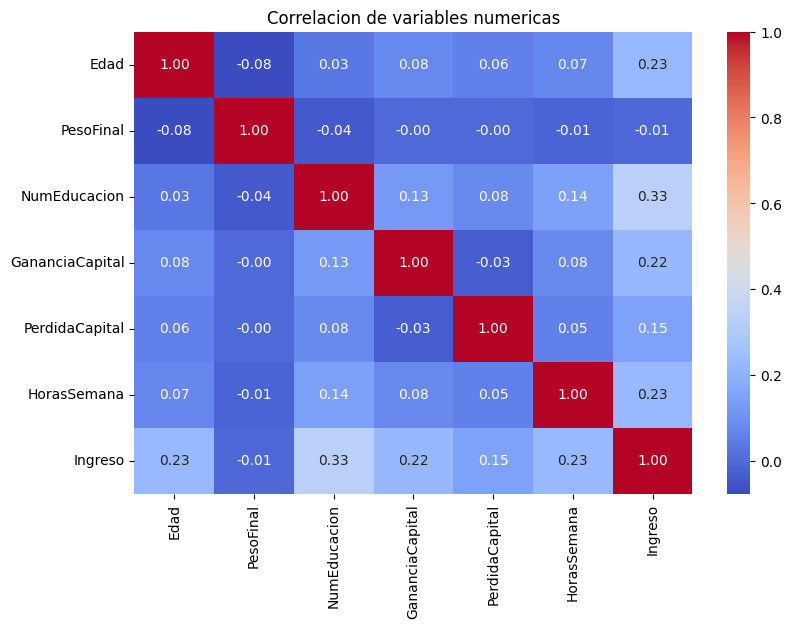

In [45]:
### Mapa de calor de correlacion entre variables numericas
plt.figure(figsize=(9,6))
sns.heatmap(datosSalario[['Edad','PesoFinal','NumEducacion','GananciaCapital',
                          'PerdidaCapital','HorasSemana','Ingreso']].corr(),
            annot=True, fmt='.2f', cmap='coolwarm')
plt.title("Correlacion de variables numericas")
plt.show()

#### Analisis
- NumEducacion, Edad, HorasSemana y GananciaCapital son las variables con mayor correlacion positiva con el Ingreso
- PesoFinal casi no tiene correlacion con el Ingreso (cerca de 0)
- No hay variables numericas muy correlacionadas entre ellas, por eso se pueden usar todas en los modelos

## **PREPARACION DE LOS DATOS**

#### Se requiere generar una nueva columna "TrabajoExtra"
- HorasSemana > 40 = 1 (trabaja mas de la jornada completa)
- Caso contrario = 0

In [46]:
df05 = df04.withColumn('TrabajoExtra', F.when(F.col('HorasSemana') > 40, 1).otherwise(0))
df05.show(4)

+----+------------+---------+------------+------------+------------------+---------------+-------------+-----+------+---------------+--------------+-----------+-------------+-------+------------+
|Edad|ClaseTrabajo|PesoFinal|   Educacion|NumEducacion|          EdoCivil|      Ocupacion|     Relacion| Raza|Genero|GananciaCapital|PerdidaCapital|HorasSemana|   PaisOrigen|Ingreso|TrabajoExtra|
+----+------------+---------+------------+------------+------------------+---------------+-------------+-----+------+---------------+--------------+-----------+-------------+-------+------------+
|  31|   Local-gov|   125927|     7th-8th|           4|Married-civ-spouse|Farming-fishing|      Husband|White|  Male|              0|             0|         40|United-States|      0|           0|
|  46| Federal-gov|   167381|     HS-grad|           9|Married-civ-spouse|   Adm-clerical|         Wife|White|Female|              0|             0|         40|United-States|      1|           0|
|  54|     Private| 

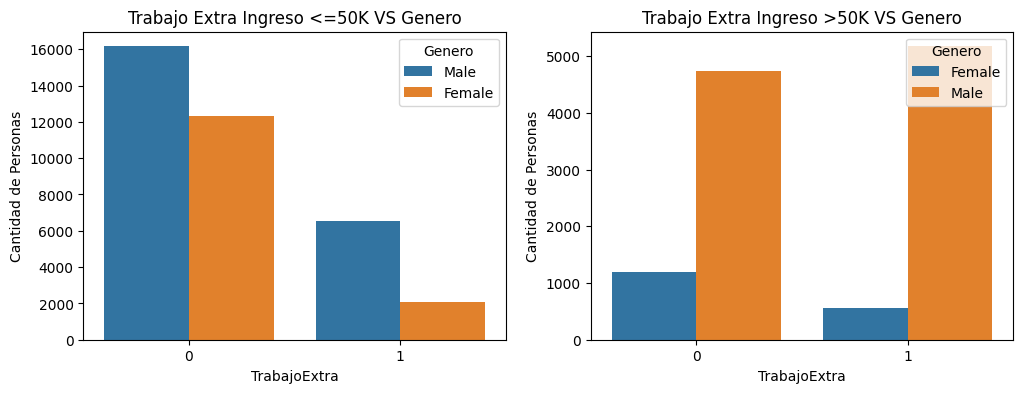

In [47]:
####################
# Graficas de Trabajo Extra segun Ingreso vs Genero
####################
pandasDatos = df05.toPandas()

fig, matrix = plt.subplots(1,2, figsize=(12,4))

matrix[0].set_title("Trabajo Extra Ingreso <=50K VS Genero")
matrix[0].set_ylabel("Cantidad de Personas")
matrix0 = sns.countplot(data=pandasDatos.loc[pandasDatos['Ingreso'] == 0], x = 'TrabajoExtra', hue = 'Genero', ax = matrix[0])
matrix[1].set_title("Trabajo Extra Ingreso >50K VS Genero")
matrix[1].set_ylabel("Cantidad de Personas")
matrix1 = sns.countplot(data=pandasDatos.loc[pandasDatos['Ingreso'] == 1], x = 'TrabajoExtra', hue = 'Genero', ax = matrix[1])

### Analisis
- En el grupo que gana >50K hay una proporcion mucho mayor de personas que trabajan mas de 40 horas
- En los dos grupos los hombres son mayoria

#### **JUSTIFICAR LA SALIDA DE LAS VARIABLES PesoFinal y Educacion**
- **PesoFinal**: es un peso que usa el censo para saber cuantas personas representa cada registro, no es una caracteristica de la persona y casi no tiene correlacion con el Ingreso
- **Educacion**: dice lo mismo que NumEducacion pero en texto, dejar las dos seria repetir informacion

In [48]:
###### Se eliminan las columnas PesoFinal y Educacion
df06 = df05.drop('PesoFinal','Educacion')
## Verificar
df06.columns

['Edad',
 'ClaseTrabajo',
 'NumEducacion',
 'EdoCivil',
 'Ocupacion',
 'Relacion',
 'Raza',
 'Genero',
 'GananciaCapital',
 'PerdidaCapital',
 'HorasSemana',
 'PaisOrigen',
 'Ingreso',
 'TrabajoExtra']

### **Cambio de variables Categoricas**
- **StringIndexer**: cambia cada categoria a un numero (ejemplo: Male=0, Female=1)
- **OneHotEncoder**: convierte ese numero en columnas de 0 y 1, para que el modelo no crea que una categoria es "mayor" que otra
- **VectorAssembler**: junta todas las variables en un solo vector
- **StandardScaler**: pone las variables numericas en la misma escala (por ejemplo GananciaCapital llega a 99999 y NumEducacion solo a 16)
- Todo se hace en SECUENCIA o ETAPAS con un **PIPELINE**

In [49]:
## Columnas categoricas y numericas
categoricas = ['ClaseTrabajo','EdoCivil','Ocupacion','Relacion','Raza','Genero','PaisOrigen']
numericas   = ['Edad','NumEducacion','GananciaCapital','PerdidaCapital','HorasSemana','TrabajoExtra']

## Se hace un indice para cada columna categorica
indice = [StringIndexer(inputCol=columna, outputCol=columna+"_IND", handleInvalid='keep')
            for columna in categoricas]

## Se codifican las categorias en columnas de 0 y 1
codificador = OneHotEncoder(inputCols=[columna+"_IND" for columna in categoricas],
                            outputCols=[columna+"_OHE" for columna in categoricas])

## Se hace uso del vector ensamblador para el uso de los modelos
ensamblador = VectorAssembler(inputCols=numericas + [columna+"_OHE" for columna in categoricas],
                              outputCol='VectorDatos')

## Se escalan los datos (withMean=False para que no queden valores negativos, NaiveBayes no los acepta)
escalador = StandardScaler(inputCol='VectorDatos', outputCol='Independientes',
                           withMean=False, withStd=True)

In [50]:
### Se crea el PIPELINE con todas las etapas
pipeBD = Pipeline(stages=indice + [codificador, ensamblador, escalador])

### Se crea un nuevo objeto df para tener secuencia en las versiones
modeloPipe = pipeBD.fit(df06)
df07 = modeloPipe.transform(df06)
df07.select('VectorDatos','Independientes','Ingreso').show(5)

+--------------------+--------------------+-------+
|         VectorDatos|      Independientes|Ingreso|
+--------------------+--------------------+-------+
|(89,[0,1,4,8,14,3...|(89,[0,1,4,8,14,3...|      0|
|(89,[0,1,4,11,14,...|(89,[0,1,4,11,14,...|      1|
|(89,[0,1,4,6,15,3...|(89,[0,1,4,6,15,3...|      0|
|(89,[0,1,4,5,6,16...|(89,[0,1,4,5,6,16...|      0|
|(89,[0,1,3,4,8,14...|(89,[0,1,3,4,8,14...|      1|
+--------------------+--------------------+-------+
only showing top 5 rows



In [51]:
### Se guardan los nombres de cada posicion del vector (sirve para ver la importancia de variables)
atributos = df07.schema['VectorDatos'].metadata['ml_attr']['attrs']
nombresVariables = sorted([(a['idx'], a['name']) for tipo in atributos for a in atributos[tipo]])
nombresVariables = [nombre for idx, nombre in nombresVariables]
print(f"Numero de variables independientes = {len(nombresVariables)}")

Numero de variables independientes = 89


#### **Division de Datos en variables Independientes y dependientes**
- Se usara el sistema 80% y 20%
- 80% para entrenamiento de los datos (el modelo sabe las respuestas)
- 20% para prueba (el modelo no conoce respuestas)
- Se calcula el porcentaje de valores positivos de la variable dependiente (Ingreso=1)

In [52]:
### Division de conjuntos de entrenamiento y prueba
df08 = df07.select(['Independientes','Ingreso'])

### Division por aleatoriedad (seed para que siempre salga la misma division)
entrenamiento, prueba = df08.randomSplit([0.8,0.2], seed=1255)

In [53]:
### Revision de porcentaje en conjunto de entrenamiento y prueba (Ingreso=1)
totalPersonas = df08.count()
totalIngresoAlto = df08.where("Ingreso == 1").count()
totalEntrenamiento = entrenamiento.count()
entreIngresoAlto = entrenamiento.where("Ingreso == 1").count()
totalPrueba = prueba.count()
pruebaIngresoAlto = prueba.where("Ingreso == 1").count()

print(f"Total personas = {totalPersonas}")
print(f"Total personas con Ingreso >50K = {totalIngresoAlto}")
print(f"Total porcentaje con Ingreso >50K = {round((totalIngresoAlto/totalPersonas)*100,2)}%")
print(f"Personas en Entrenamiento = {totalEntrenamiento}")
print(f"Entrenamiento Porcentaje con Ingreso >50K = {round((entreIngresoAlto/totalEntrenamiento)*100,2)}%")
print(f"Personas en Prueba = {totalPrueba}")
print(f"Prueba Porcentaje con Ingreso >50K = {round((pruebaIngresoAlto/totalPrueba)*100,2)}%")

Total personas = 48789
Total personas con Ingreso >50K = 11681
Total porcentaje con Ingreso >50K = 23.94%
Personas en Entrenamiento = 38969
Entrenamiento Porcentaje con Ingreso >50K = 23.9%
Personas en Prueba = 9820
Prueba Porcentaje con Ingreso >50K = 24.1%


- El porcentaje de personas con Ingreso >50K es casi igual en entrenamiento y prueba, entonces la division quedo bien hecha

## ***Modelos MLlib***
- Logistic Regression
- Decision Tree
- Random Forest
- Gradient Boosted Trees
- Support Vector Machine
- Naive Bayes
- Multilayer Perceptron Classifier

#### **Metricas de evaluacion**
- **Exactitud (accuracy)**: porcentaje de predicciones correctas
- **Precision**: de los que el modelo dijo que eran de una clase, cuantos si lo eran
- **Recall**: de los que realmente eran de una clase, cuantos encontro el modelo
- **F1**: combina precision y recall en una sola medida
- **AUC**: area bajo la curva ROC, mide que tan bien el modelo separa las dos clases (1 es perfecto, 0.5 es como adivinar)

### Logistic Regression

In [54]:
### Regresion Logistica
### Se instala el modelo
RegLog = LogisticRegression(featuresCol='Independientes', labelCol='Ingreso', maxIter=100)

### Se entrena el modelo sobre los datos de entrenamiento
modeloRL = RegLog.fit(entrenamiento)

### Se hacen predicciones sobre datos de prueba
prediccionRL = modeloRL.transform(prueba)

### Se observan las predicciones
prediccionRL.show(5)

+--------------------+-------+--------------------+--------------------+----------+
|      Independientes|Ingreso|       rawPrediction|         probability|prediction|
+--------------------+-------+--------------------+--------------------+----------+
|(89,[0,1,2,4,5,6,...|      1|[-6.3920326209339...|[0.00167204798035...|       1.0|
|(89,[0,1,2,4,5,6,...|      1|[-5.9053226182523...|[0.00271749761946...|       1.0|
|(89,[0,1,2,4,5,6,...|      1|[-2.1367119323333...|[0.10557948739889...|       1.0|
|(89,[0,1,2,4,5,6,...|      1|[-34.428015915492...|[1.11712729982615...|       1.0|
|(89,[0,1,2,4,5,6,...|      1|[-34.235911532708...|[1.35373151178521...|       1.0|
+--------------------+-------+--------------------+--------------------+----------+
only showing top 5 rows



### Evaluacion ModeloRL

In [55]:
### accuracy : Exactitud
accuracyRL = MulticlassClassificationEvaluator(labelCol='Ingreso',
                                               metricName='accuracy').evaluate(prediccionRL)
precisionRL = MulticlassClassificationEvaluator(labelCol='Ingreso',
                                                metricName='weightedPrecision').evaluate(prediccionRL)
recallRL = MulticlassClassificationEvaluator(labelCol='Ingreso',
                                                metricName='weightedRecall').evaluate(prediccionRL)
f1RL = MulticlassClassificationEvaluator(labelCol='Ingreso',
                                                metricName='f1').evaluate(prediccionRL)
### AUC : area bajo la curva ROC
aucRL = BinaryClassificationEvaluator(labelCol='Ingreso', rawPredictionCol='rawPrediction',
                                                metricName='areaUnderROC').evaluate(prediccionRL)

# Se imprimen
print(f"\t Exactitud en modelo RL = \t\t {round(accuracyRL*100,2)} %")
print(f"\t Precision en modelo RL = \t\t {round(precisionRL*100,2)} %")
print(f"\t Recall en modelo RL = \t\t {round(recallRL*100,2)} %")
print(f"\t F1 en modelo RL = \t\t\t {round(f1RL*100,2)} %")
print(f"\t AUC en modelo RL = \t\t\t {round(aucRL,4)}")

	 Exactitud en modelo RL = 		 85.0 %
	 Precision en modelo RL = 		 84.31 %
	 Recall en modelo RL = 		 85.0 %
	 F1 en modelo RL = 			 84.38 %
	 AUC en modelo RL = 			 0.9008


In [56]:
### Se sacan los valores reales y las predicciones para la matriz de confusion
y_trueRL = prediccionRL.select('Ingreso').toPandas()
y_predRL = prediccionRL.select('prediction').toPandas()
confMatrixRL = confusion_matrix(y_trueRL, y_predRL)

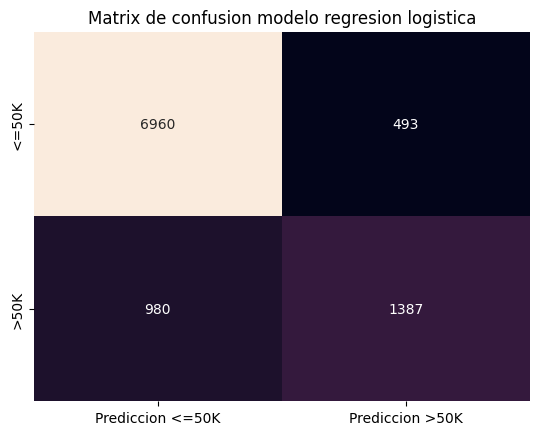

In [57]:
### Graficas modelo RL
plt.title('Matrix de confusion modelo regresion logistica')
sns.heatmap(confMatrixRL, annot=True, fmt='d', cbar=False,
            xticklabels=['Prediccion <=50K', 'Prediccion >50K'],
            yticklabels=['<=50K', '>50K'])

plt.show()

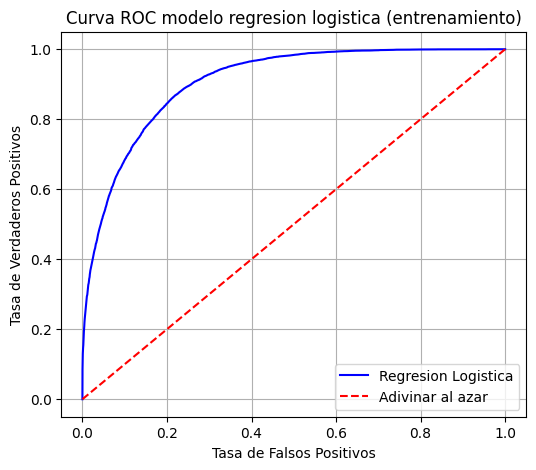

In [58]:
### La regresion logistica tiene summary, entonces se puede pintar la curva ROC
RO_RL = modeloRL.summary.roc.toPandas()

plt.figure(figsize=(6,5))
plt.plot(RO_RL['FPR'], RO_RL['TPR'], color='blue', label='Regresion Logistica')
plt.plot([0,1], [0,1], 'r--', label='Adivinar al azar')
plt.title('Curva ROC modelo regresion logistica (entrenamiento)')
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.legend()
plt.grid()
plt.show()

### Decision Tree

In [59]:
### Arbol de Decision
### Se instala el modelo (profundidad maxima de 8 niveles)
ArbDec = DecisionTreeClassifier(featuresCol='Independientes', labelCol='Ingreso', maxDepth=8)

### Se entrena el modelo sobre los datos de entrenamiento
modeloDT = ArbDec.fit(entrenamiento)

### Se hacen predicciones sobre datos de prueba
prediccionDT = modeloDT.transform(prueba)

### Se observan las predicciones
prediccionDT.show(5)

+--------------------+-------+-------------+--------------------+----------+
|      Independientes|Ingreso|rawPrediction|         probability|prediction|
+--------------------+-------+-------------+--------------------+----------+
|(89,[0,1,2,4,5,6,...|      1|  [0.0,642.0]|           [0.0,1.0]|       1.0|
|(89,[0,1,2,4,5,6,...|      1|  [0.0,642.0]|           [0.0,1.0]|       1.0|
|(89,[0,1,2,4,5,6,...|      1| [49.0,130.0]|[0.27374301675977...|       1.0|
|(89,[0,1,2,4,5,6,...|      1|  [0.0,642.0]|           [0.0,1.0]|       1.0|
|(89,[0,1,2,4,5,6,...|      1|  [0.0,642.0]|           [0.0,1.0]|       1.0|
+--------------------+-------+-------------+--------------------+----------+
only showing top 5 rows



### Evaluacion ModeloDT

In [60]:
### accuracy : Exactitud
accuracyDT = MulticlassClassificationEvaluator(labelCol='Ingreso',
                                               metricName='accuracy').evaluate(prediccionDT)
precisionDT = MulticlassClassificationEvaluator(labelCol='Ingreso',
                                                metricName='weightedPrecision').evaluate(prediccionDT)
recallDT = MulticlassClassificationEvaluator(labelCol='Ingreso',
                                                metricName='weightedRecall').evaluate(prediccionDT)
f1DT = MulticlassClassificationEvaluator(labelCol='Ingreso',
                                                metricName='f1').evaluate(prediccionDT)
### AUC : area bajo la curva ROC
aucDT = BinaryClassificationEvaluator(labelCol='Ingreso', rawPredictionCol='rawPrediction',
                                                metricName='areaUnderROC').evaluate(prediccionDT)

# Se imprimen
print(f"\t Exactitud en modelo DT = \t\t {round(accuracyDT*100,2)} %")
print(f"\t Precision en modelo DT = \t\t {round(precisionDT*100,2)} %")
print(f"\t Recall en modelo DT = \t\t {round(recallDT*100,2)} %")
print(f"\t F1 en modelo DT = \t\t\t {round(f1DT*100,2)} %")
print(f"\t AUC en modelo DT = \t\t\t {round(aucDT,4)}")

	 Exactitud en modelo DT = 		 84.83 %
	 Precision en modelo DT = 		 84.1 %
	 Recall en modelo DT = 		 84.83 %
	 F1 en modelo DT = 			 83.84 %
	 AUC en modelo DT = 			 0.7074


In [61]:
### Se sacan los valores reales y las predicciones para la matriz de confusion
y_trueDT = prediccionDT.select('Ingreso').toPandas()
y_predDT = prediccionDT.select('prediction').toPandas()
confMatrixDT = confusion_matrix(y_trueDT, y_predDT)

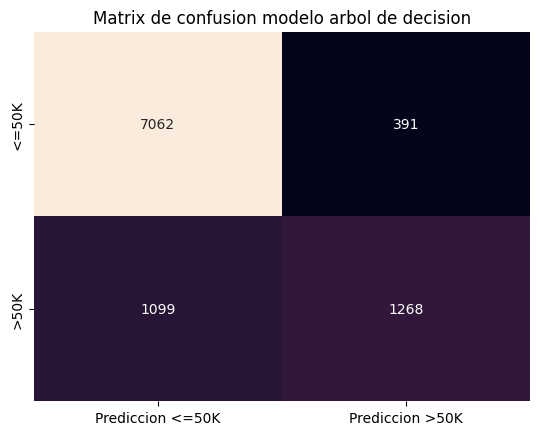

In [62]:
### Graficas modelo DT
plt.title('Matrix de confusion modelo arbol de decision')
sns.heatmap(confMatrixDT, annot=True, fmt='d', cbar=False,
            xticklabels=['Prediccion <=50K', 'Prediccion >50K'],
            yticklabels=['<=50K', '>50K'])

plt.show()

### Random Forest

In [63]:
### Random Forest
### Se instala el modelo (50 arboles con profundidad maxima de 8)
RanFor = RandomForestClassifier(featuresCol='Independientes', labelCol='Ingreso', numTrees=50, maxDepth=8, seed=1255)

### Se entrena el modelo sobre los datos de entrenamiento
modeloRF = RanFor.fit(entrenamiento)

### Se hacen predicciones sobre datos de prueba
prediccionRF = modeloRF.transform(prueba)

### Se observan las predicciones
prediccionRF.show(5)

26/11/18 23:11:01 WARN DAGScheduler: Broadcasting large task binary with size 1364.9 KiB


+--------------------+-------+--------------------+--------------------+----------+
|      Independientes|Ingreso|       rawPrediction|         probability|prediction|
+--------------------+-------+--------------------+--------------------+----------+
|(89,[0,1,2,4,5,6,...|      1|[7.94065128283387...|[0.15881302565667...|       1.0|
|(89,[0,1,2,4,5,6,...|      1|[8.32504161976739...|[0.16650083239534...|       1.0|
|(89,[0,1,2,4,5,6,...|      1|[23.7005591354040...|[0.47401118270808...|       1.0|
|(89,[0,1,2,4,5,6,...|      1|[7.94065128283387...|[0.15881302565667...|       1.0|
|(89,[0,1,2,4,5,6,...|      1|[7.94065128283387...|[0.15881302565667...|       1.0|
+--------------------+-------+--------------------+--------------------+----------+
only showing top 5 rows



### Evaluacion ModeloRF

In [64]:
### accuracy : Exactitud
accuracyRF = MulticlassClassificationEvaluator(labelCol='Ingreso',
                                               metricName='accuracy').evaluate(prediccionRF)
precisionRF = MulticlassClassificationEvaluator(labelCol='Ingreso',
                                                metricName='weightedPrecision').evaluate(prediccionRF)
recallRF = MulticlassClassificationEvaluator(labelCol='Ingreso',
                                                metricName='weightedRecall').evaluate(prediccionRF)
f1RF = MulticlassClassificationEvaluator(labelCol='Ingreso',
                                                metricName='f1').evaluate(prediccionRF)
### AUC : area bajo la curva ROC
aucRF = BinaryClassificationEvaluator(labelCol='Ingreso', rawPredictionCol='rawPrediction',
                                                metricName='areaUnderROC').evaluate(prediccionRF)

# Se imprimen
print(f"\t Exactitud en modelo RF = \t\t {round(accuracyRF*100,2)} %")
print(f"\t Precision en modelo RF = \t\t {round(precisionRF*100,2)} %")
print(f"\t Recall en modelo RF = \t\t {round(recallRF*100,2)} %")
print(f"\t F1 en modelo RF = \t\t\t {round(f1RF*100,2)} %")
print(f"\t AUC en modelo RF = \t\t\t {round(aucRF,4)}")

	 Exactitud en modelo RF = 		 84.19 %
	 Precision en modelo RF = 		 83.76 %
	 Recall en modelo RF = 		 84.19 %
	 F1 en modelo RF = 			 82.47 %
	 AUC en modelo RF = 			 0.8977


In [65]:
### Se sacan los valores reales y las predicciones para la matriz de confusion
y_trueRF = prediccionRF.select('Ingreso').toPandas()
y_predRF = prediccionRF.select('prediction').toPandas()
confMatrixRF = confusion_matrix(y_trueRF, y_predRF)

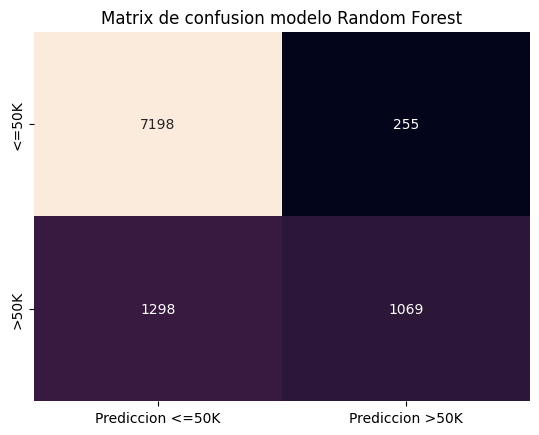

In [66]:
### Graficas modelo RF
plt.title('Matrix de confusion modelo Random Forest')
sns.heatmap(confMatrixRF, annot=True, fmt='d', cbar=False,
            xticklabels=['Prediccion <=50K', 'Prediccion >50K'],
            yticklabels=['<=50K', '>50K'])

plt.show()

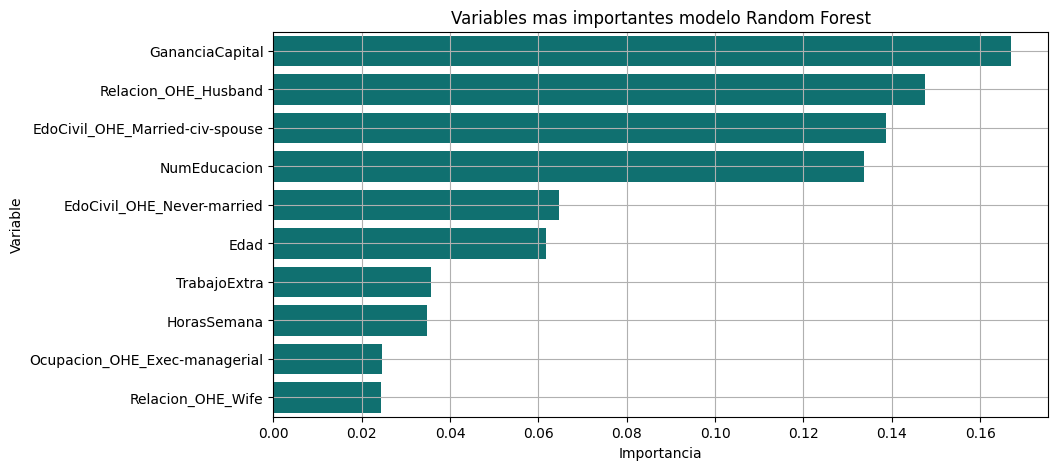

In [67]:
### Importancia de las variables segun el modelo RF (10 mas importantes)
importanciaRF = pd.DataFrame({'Variable': nombresVariables,
                              'Importancia': modeloRF.featureImportances.toArray()})
importanciaRF = importanciaRF.sort_values('Importancia', ascending=False).head(10)

plt.figure(figsize=(10,5))
sns.barplot(data=importanciaRF, x='Importancia', y='Variable', color='teal')
plt.title('Variables mas importantes modelo Random Forest')
plt.grid()
plt.show()

#### Analisis
- La grafica muestra cuales variables uso mas el modelo RF para decidir si una persona gana mas o menos de 50K
- Se espera que aparezcan variables como el estado civil (casado), la relacion (esposo), el nivel educativo, la edad y la ganancia de capital, que fueron las que mas se diferenciaban en las graficas

### Gradient Boosted Trees

In [68]:
### Gradient Boosted Trees
### Se instala el modelo (30 arboles, cada uno corrige los errores del anterior)
GraBoo = GBTClassifier(featuresCol='Independientes', labelCol='Ingreso', maxIter=30, maxDepth=5, seed=1255)

### Se entrena el modelo sobre los datos de entrenamiento
modeloGBT = GraBoo.fit(entrenamiento)

### Se hacen predicciones sobre datos de prueba
prediccionGBT = modeloGBT.transform(prueba)

### Se observan las predicciones
prediccionGBT.show(5)

+--------------------+-------+--------------------+--------------------+----------+
|      Independientes|Ingreso|       rawPrediction|         probability|prediction|
+--------------------+-------+--------------------+--------------------+----------+
|(89,[0,1,2,4,5,6,...|      1|[-1.5945264539661...|[0.03957976586381...|       1.0|
|(89,[0,1,2,4,5,6,...|      1|[-1.5374731728750...|[0.04415260488146...|       1.0|
|(89,[0,1,2,4,5,6,...|      1|[-0.3740864378480...|[0.32121955233290...|       1.0|
|(89,[0,1,2,4,5,6,...|      1|[-1.5945264539661...|[0.03957976586381...|       1.0|
|(89,[0,1,2,4,5,6,...|      1|[-1.5901124525213...|[0.03991671394175...|       1.0|
+--------------------+-------+--------------------+--------------------+----------+
only showing top 5 rows



### Evaluacion ModeloGBT

In [69]:
### accuracy : Exactitud
accuracyGBT = MulticlassClassificationEvaluator(labelCol='Ingreso',
                                               metricName='accuracy').evaluate(prediccionGBT)
precisionGBT = MulticlassClassificationEvaluator(labelCol='Ingreso',
                                                metricName='weightedPrecision').evaluate(prediccionGBT)
recallGBT = MulticlassClassificationEvaluator(labelCol='Ingreso',
                                                metricName='weightedRecall').evaluate(prediccionGBT)
f1GBT = MulticlassClassificationEvaluator(labelCol='Ingreso',
                                                metricName='f1').evaluate(prediccionGBT)
### AUC : area bajo la curva ROC
aucGBT = BinaryClassificationEvaluator(labelCol='Ingreso', rawPredictionCol='rawPrediction',
                                                metricName='areaUnderROC').evaluate(prediccionGBT)

# Se imprimen
print(f"\t Exactitud en modelo GBT = \t\t {round(accuracyGBT*100,2)} %")
print(f"\t Precision en modelo GBT = \t\t {round(precisionGBT*100,2)} %")
print(f"\t Recall en modelo GBT = \t\t {round(recallGBT*100,2)} %")
print(f"\t F1 en modelo GBT = \t\t\t {round(f1GBT*100,2)} %")
print(f"\t AUC en modelo GBT = \t\t\t {round(aucGBT,4)}")

	 Exactitud en modelo GBT = 		 85.76 %
	 Precision en modelo GBT = 		 85.14 %
	 Recall en modelo GBT = 		 85.76 %
	 F1 en modelo GBT = 			 85.06 %
	 AUC en modelo GBT = 			 0.9092


In [70]:
### Se sacan los valores reales y las predicciones para la matriz de confusion
y_trueGBT = prediccionGBT.select('Ingreso').toPandas()
y_predGBT = prediccionGBT.select('prediction').toPandas()
confMatrixGBT = confusion_matrix(y_trueGBT, y_predGBT)

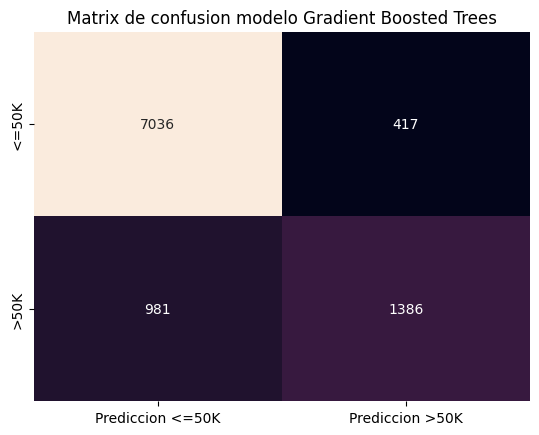

In [71]:
### Graficas modelo GBT
plt.title('Matrix de confusion modelo Gradient Boosted Trees')
sns.heatmap(confMatrixGBT, annot=True, fmt='d', cbar=False,
            xticklabels=['Prediccion <=50K', 'Prediccion >50K'],
            yticklabels=['<=50K', '>50K'])

plt.show()

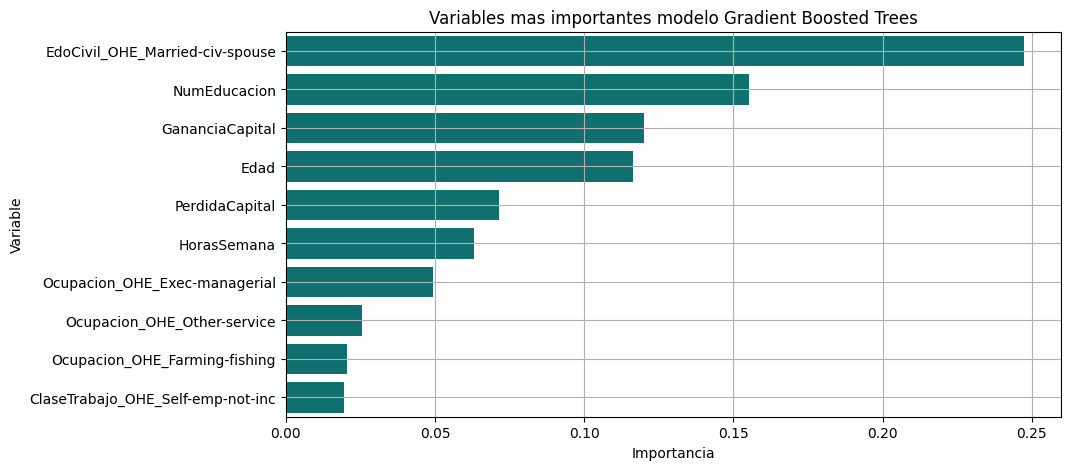

In [72]:
### Importancia de las variables segun el modelo GBT (10 mas importantes)
importanciaGBT = pd.DataFrame({'Variable': nombresVariables,
                              'Importancia': modeloGBT.featureImportances.toArray()})
importanciaGBT = importanciaGBT.sort_values('Importancia', ascending=False).head(10)

plt.figure(figsize=(10,5))
sns.barplot(data=importanciaGBT, x='Importancia', y='Variable', color='teal')
plt.title('Variables mas importantes modelo Gradient Boosted Trees')
plt.grid()
plt.show()

#### Analisis
- La grafica muestra cuales variables uso mas el modelo GBT para decidir si una persona gana mas o menos de 50K
- Se espera que aparezcan variables como el estado civil (casado), la relacion (esposo), el nivel educativo, la edad y la ganancia de capital, que fueron las que mas se diferenciaban en las graficas

### Support Vector Machine

In [73]:
### Maquina de soporte vectorial (Lineal)
### Se instala el modelo
SopVec = LinearSVC(featuresCol='Independientes', labelCol='Ingreso', maxIter=50)

### Se entrena el modelo sobre los datos de entrenamiento
modeloSVM = SopVec.fit(entrenamiento)

### Se hacen predicciones sobre datos de prueba
prediccionSVM = modeloSVM.transform(prueba)

### Se observan las predicciones
prediccionSVM.show(5)

+--------------------+-------+--------------------+----------+
|      Independientes|Ingreso|       rawPrediction|prediction|
+--------------------+-------+--------------------+----------+
|(89,[0,1,2,4,5,6,...|      1|[-4.7656012881499...|       1.0|
|(89,[0,1,2,4,5,6,...|      1|[-4.3874899781374...|       1.0|
|(89,[0,1,2,4,5,6,...|      1|[-1.5261188152080...|       1.0|
|(89,[0,1,2,4,5,6,...|      1|[-25.326019634951...|       1.0|
|(89,[0,1,2,4,5,6,...|      1|[-25.185551500028...|       1.0|
+--------------------+-------+--------------------+----------+
only showing top 5 rows



### Evaluacion ModeloSVM

In [74]:
### accuracy : Exactitud
accuracySVM = MulticlassClassificationEvaluator(labelCol='Ingreso',
                                               metricName='accuracy').evaluate(prediccionSVM)
precisionSVM = MulticlassClassificationEvaluator(labelCol='Ingreso',
                                                metricName='weightedPrecision').evaluate(prediccionSVM)
recallSVM = MulticlassClassificationEvaluator(labelCol='Ingreso',
                                                metricName='weightedRecall').evaluate(prediccionSVM)
f1SVM = MulticlassClassificationEvaluator(labelCol='Ingreso',
                                                metricName='f1').evaluate(prediccionSVM)
### AUC : area bajo la curva ROC
aucSVM = BinaryClassificationEvaluator(labelCol='Ingreso', rawPredictionCol='rawPrediction',
                                                metricName='areaUnderROC').evaluate(prediccionSVM)

# Se imprimen
print(f"\t Exactitud en modelo SVM = \t\t {round(accuracySVM*100,2)} %")
print(f"\t Precision en modelo SVM = \t\t {round(precisionSVM*100,2)} %")
print(f"\t Recall en modelo SVM = \t\t {round(recallSVM*100,2)} %")
print(f"\t F1 en modelo SVM = \t\t\t {round(f1SVM*100,2)} %")
print(f"\t AUC en modelo SVM = \t\t\t {round(aucSVM,4)}")

	 Exactitud en modelo SVM = 		 85.24 %
	 Precision en modelo SVM = 		 84.56 %
	 Recall en modelo SVM = 		 85.24 %
	 F1 en modelo SVM = 			 84.57 %
	 AUC en modelo SVM = 			 0.8981


In [75]:
### Se sacan los valores reales y las predicciones para la matriz de confusion
y_trueSVM = prediccionSVM.select('Ingreso').toPandas()
y_predSVM = prediccionSVM.select('prediction').toPandas()
confMatrixSVM = confusion_matrix(y_trueSVM, y_predSVM)

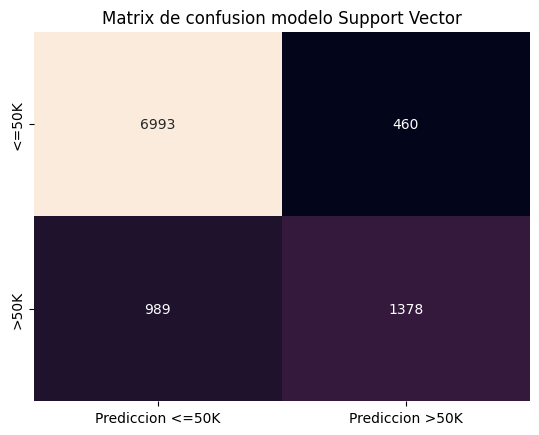

In [76]:
### Graficas modelo SVM
plt.title('Matrix de confusion modelo Support Vector')
sns.heatmap(confMatrixSVM, annot=True, fmt='d', cbar=False,
            xticklabels=['Prediccion <=50K', 'Prediccion >50K'],
            yticklabels=['<=50K', '>50K'])

plt.show()

### Naive Bayes

In [77]:
### Naive Bayes
### Se instala el modelo (multinomial, necesita datos sin valores negativos)
NaiBay = NaiveBayes(featuresCol='Independientes', labelCol='Ingreso', modelType='multinomial')

### Se entrena el modelo sobre los datos de entrenamiento
modeloNB = NaiBay.fit(entrenamiento)

### Se hacen predicciones sobre datos de prueba
prediccionNB = modeloNB.transform(prueba)

### Se observan las predicciones
prediccionNB.show(5)

+--------------------+-------+--------------------+--------------------+----------+
|      Independientes|Ingreso|       rawPrediction|         probability|prediction|
+--------------------+-------+--------------------+--------------------+----------+
|(89,[0,1,2,4,5,6,...|      1|[-111.50647159560...|[2.41675963039435...|       1.0|
|(89,[0,1,2,4,5,6,...|      1|[-109.15124811337...|[2.67709921459360...|       1.0|
|(89,[0,1,2,4,5,6,...|      1|[-97.712461667357...|[9.78626224629780...|       1.0|
|(89,[0,1,2,4,5,6,...|      1|[-196.98777936666...|[1.34200360025024...|       1.0|
|(89,[0,1,2,4,5,6,...|      1|[-195.47070319031...|[1.41805257390021...|       1.0|
+--------------------+-------+--------------------+--------------------+----------+
only showing top 5 rows



### Evaluacion ModeloNB

In [78]:
### accuracy : Exactitud
accuracyNB = MulticlassClassificationEvaluator(labelCol='Ingreso',
                                               metricName='accuracy').evaluate(prediccionNB)
precisionNB = MulticlassClassificationEvaluator(labelCol='Ingreso',
                                                metricName='weightedPrecision').evaluate(prediccionNB)
recallNB = MulticlassClassificationEvaluator(labelCol='Ingreso',
                                                metricName='weightedRecall').evaluate(prediccionNB)
f1NB = MulticlassClassificationEvaluator(labelCol='Ingreso',
                                                metricName='f1').evaluate(prediccionNB)
### AUC : area bajo la curva ROC
aucNB = BinaryClassificationEvaluator(labelCol='Ingreso', rawPredictionCol='rawPrediction',
                                                metricName='areaUnderROC').evaluate(prediccionNB)

# Se imprimen
print(f"\t Exactitud en modelo NB = \t\t {round(accuracyNB*100,2)} %")
print(f"\t Precision en modelo NB = \t\t {round(precisionNB*100,2)} %")
print(f"\t Recall en modelo NB = \t\t {round(recallNB*100,2)} %")
print(f"\t F1 en modelo NB = \t\t\t {round(f1NB*100,2)} %")
print(f"\t AUC en modelo NB = \t\t\t {round(aucNB,4)}")

	 Exactitud en modelo NB = 		 76.29 %
	 Precision en modelo NB = 		 82.54 %
	 Recall en modelo NB = 		 76.29 %
	 F1 en modelo NB = 			 77.8 %
	 AUC en modelo NB = 			 0.5652


In [79]:
### Se sacan los valores reales y las predicciones para la matriz de confusion
y_trueNB = prediccionNB.select('Ingreso').toPandas()
y_predNB = prediccionNB.select('prediction').toPandas()
confMatrixNB = confusion_matrix(y_trueNB, y_predNB)

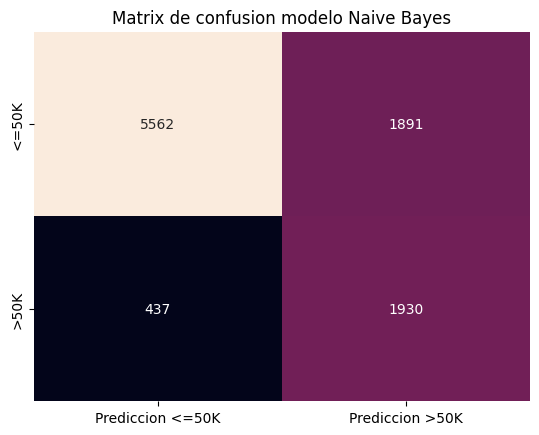

In [80]:
### Graficas modelo NB
plt.title('Matrix de confusion modelo Naive Bayes')
sns.heatmap(confMatrixNB, annot=True, fmt='d', cbar=False,
            xticklabels=['Prediccion <=50K', 'Prediccion >50K'],
            yticklabels=['<=50K', '>50K'])

plt.show()

### Multilayer Perceptron Classifier

In [81]:
### Perceptron Multicapa
### Se calcula cuantas variables independientes entran al modelo (capa de entrada)
numEntradas = len(entrenamiento.first()['Independientes'])

### Capas: entrada, 2 capas ocultas y salida (2 clases: Ingreso 0 o 1)
capas = [numEntradas, 16, 8, 2]

### Se instala el modelo
PerMul = MultilayerPerceptronClassifier(featuresCol='Independientes', labelCol='Ingreso',
                                        layers=capas, maxIter=100, seed=1255)

### Se entrena el modelo sobre los datos de entrenamiento
modeloMLP = PerMul.fit(entrenamiento)

### Se hacen predicciones sobre datos de prueba
prediccionMLP = modeloMLP.transform(prueba)

### Se observan las predicciones
prediccionMLP.show(5)

+--------------------+-------+--------------------+--------------------+----------+
|      Independientes|Ingreso|       rawPrediction|         probability|prediction|
+--------------------+-------+--------------------+--------------------+----------+
|(89,[0,1,2,4,5,6,...|      1|[-2.5264621114437...|[0.00417278692311...|       1.0|
|(89,[0,1,2,4,5,6,...|      1|[-2.5213418157771...|[0.00421292177571...|       1.0|
|(89,[0,1,2,4,5,6,...|      1|[-0.7283450591626...|[0.08087190033441...|       1.0|
|(89,[0,1,2,4,5,6,...|      1|[-2.5868806718112...|[0.00377483612605...|       1.0|
|(89,[0,1,2,4,5,6,...|      1|[-2.5869669889716...|[0.00377412644294...|       1.0|
+--------------------+-------+--------------------+--------------------+----------+
only showing top 5 rows



### Evaluacion ModeloMLP

In [ ]:
### accuracy : Exactitud
accuracyMLP = MulticlassClassificationEvaluator(labelCol='Ingreso',
                                               metricName='accuracy').evaluate(prediccionMLP)
precisionMLP = MulticlassClassificationEvaluator(labelCol='Ingreso',
                                                metricName='weightedPrecision').evaluate(prediccionMLP)
recallMLP = MulticlassClassificationEvaluator(labelCol='Ingreso',
                                                metricName='weightedRecall').evaluate(prediccionMLP)
f1MLP = MulticlassClassificationEvaluator(labelCol='Ingreso',
                                                metricName='f1').evaluate(prediccionMLP)
### AUC : area bajo la curva ROC
aucMLP = BinaryClassificationEvaluator(labelCol='Ingreso', rawPredictionCol='rawPrediction',
                                                metricName='areaUnderROC').evaluate(prediccionMLP)

# Se imprimen
print(f"\t Exactitud en modelo MLP = \t\t {round(accuracyMLP*100,2)} %")
print(f"\t Precision en modelo MLP = \t\t {round(precisionMLP*100,2)} %")
print(f"\t Recall en modelo MLP = \t\t {round(recallMLP*100,2)} %")
print(f"\t F1 en modelo MLP = \t\t\t {round(f1MLP*100,2)} %")
print(f"\t AUC en modelo MLP = \t\t\t {round(aucMLP,4)}")

In [ ]:
### Se sacan los valores reales y las predicciones para la matriz de confusion
y_trueMLP = prediccionMLP.select('Ingreso').toPandas()
y_predMLP = prediccionMLP.select('prediction').toPandas()
confMatrixMLP = confusion_matrix(y_trueMLP, y_predMLP)

In [ ]:
### Graficas modelo MLP
plt.title('Matrix de confusion modelo Perceptron Multicapa')
sns.heatmap(confMatrixMLP, annot=True, fmt='d', cbar=False,
            xticklabels=['Prediccion <=50K', 'Prediccion >50K'],
            yticklabels=['<=50K', '>50K'])

plt.show()

## **ANALISIS DE RESULTADOS**
### Comparacion de modelos

In [ ]:
### Se crea una tabla para comparar los resultados de todos los modelos
comparacion = pd.DataFrame({
    'Modelo': ['Regresion Logistica', 'Decision Tree', 'Random Forest', 'Gradient Boosted Trees',
               'Support Vector', 'Naive Bayes', 'Perceptron Multicapa'],
    'Exactitud': [accuracyRL, accuracyDT, accuracyRF, accuracyGBT, accuracySVM, accuracyNB, accuracyMLP],
    'Precision': [precisionRL, precisionDT, precisionRF, precisionGBT, precisionSVM, precisionNB, precisionMLP],
    'Recall': [recallRL, recallDT, recallRF, recallGBT, recallSVM, recallNB, recallMLP],
    'F1': [f1RL, f1DT, f1RF, f1GBT, f1SVM, f1NB, f1MLP],
    'AUC': [aucRL, aucDT, aucRF, aucGBT, aucSVM, aucNB, aucMLP]
})
comparacion[['Exactitud','Precision','Recall','F1']] = (comparacion[['Exactitud','Precision','Recall','F1']]*100).round(2)
comparacion['AUC'] = comparacion['AUC'].round(4)
comparacion = comparacion.sort_values('AUC', ascending=False).reset_index(drop=True)
comparacion

In [ ]:
### Grafica comparativa de Exactitud y F1 por modelo
comparacionGraf = comparacion.melt(id_vars='Modelo', value_vars=['Exactitud','F1'],
                                   var_name='Metrica', value_name='Porcentaje')
plt.figure(figsize=(13,5))
sns.barplot(data=comparacionGraf, x='Modelo', y='Porcentaje', hue='Metrica')
plt.axhline(y=round((1-totalIngresoAlto/totalPersonas)*100,2), color='red', linestyle='--',
            label='Linea base (decir siempre <=50K)')
plt.title('Comparacion de Exactitud y F1 de los modelos')
plt.ylim(50,100)
plt.xticks(rotation=30)
plt.legend()
plt.grid()
plt.show()

In [ ]:
### Recall de la clase >50K (cuantas personas con ingreso alto encontro cada modelo)
matrices = {'Regresion Logistica': confMatrixRL, 'Decision Tree': confMatrixDT, 'Random Forest': confMatrixRF,
            'Gradient Boosted Trees': confMatrixGBT, 'Support Vector': confMatrixSVM,
            'Naive Bayes': confMatrixNB, 'Perceptron Multicapa': confMatrixMLP}
for nombre, matriz in matrices.items():
    recallAlto = matriz[1][1] / (matriz[1][0] + matriz[1][1])
    print(f"\t Recall clase >50K en {nombre} = \t {round(recallAlto*100,2)} %")

In [ ]:
### Mejor modelo segun el AUC
mejor = comparacion.iloc[0]
print(f"El mejor modelo es {mejor['Modelo']} con AUC = {mejor['AUC']} y exactitud = {mejor['Exactitud']} %")

#### Analisis de resultados
- La **linea base** es cerca del 76%: si un modelo dijera siempre "<=50K" acertaria ese porcentaje sin aprender nada. Todos los modelos deben superar esa linea para ser utiles
- A diferencia del dataset de derrames (donde solo el 5% tenia derrame), aca el desbalance es menor (24% gana >50K), por eso los modelos si logran aprender a detectar la clase >50K
- Para comparar los modelos se usa principalmente el **AUC** y el **F1**, porque la exactitud sola no tiene en cuenta el desbalance de los datos
- En las matrices de confusion se ve que los modelos se equivocan mas con las personas que ganan >50K (las clasifican como <=50K), porque hay menos ejemplos de esa clase
- Los modelos basados en arboles (Random Forest y Gradient Boosted Trees) permiten ver la importancia de las variables, lo cual ayuda a entender por que el modelo toma sus decisiones
- Naive Bayes supone que todas las variables son independientes entre si, lo cual no se cumple en este dataset (por ejemplo EdoCivil y Relacion estan muy relacionadas), por eso es normal que tenga un rendimiento menor

## **CONCLUSIONES**

### Sobre los datos
- El dataset tiene 48.842 registros del censo de Estados Unidos de 1994, se unieron los archivos `adult.data` y `adult.test` y se cargaron desde Hadoop HDFS
- Los datos faltantes venian con "?" en ClaseTrabajo, Ocupacion y PaisOrigen; como eran menos del 6% se reemplazaron por la moda para no perder registros
- Se corrigio la variable Ingreso porque en el archivo de prueba los valores terminaban en punto, lo que habria creado 4 categorias en vez de 2
- Se eliminaron PesoFinal (no es una caracteristica de la persona) y Educacion (repite la informacion de NumEducacion)
- Solo cerca del 24% de las personas gana mas de 50K, los datos estan desbalanceados

### Sobre las variables
- El **nivel educativo** es uno de los factores que mas influye: desde el nivel de maestria la mayoria gana mas de 50K
- Las personas **casadas** y con rol de esposo o esposa tienen mucha mas probabilidad de tener ingresos altos que las solteras
- La **edad** y las **horas trabajadas** tambien influyen: las personas con ingresos altos son en promedio mayores y trabajan mas horas
- Se observa una **brecha de genero**: cerca del 30% de los hombres gana mas de 50K frente a cerca del 11% de las mujeres
- Las ocupaciones de gerentes y profesionales son las que mas personas con ingresos altos tienen

### Sobre los modelos
- Se entrenaron y evaluaron 7 modelos de MLlib: Regresion Logistica, Decision Tree, Random Forest, Gradient Boosted Trees, Support Vector, Naive Bayes y Perceptron Multicapa
- El uso de PIPELINE con StringIndexer, OneHotEncoder, VectorAssembler y StandardScaler permitio preparar los datos en etapas y dejarlos listos para todos los modelos
- El mejor modelo se escogio con el AUC y el F1 y no solo con la exactitud, porque con datos desbalanceados la exactitud puede engañar
- La mayor dificultad de los modelos fue detectar a las personas que ganan mas de 50K, porque hay menos ejemplos de esa clase

### Conclusion general
- Se cumplio con la metodologia CRISP-DM: entendimiento de los datos, preparacion, modelado y evaluacion
- PySpark y Hadoop HDFS permiten trabajar con grandes volumenes de datos de forma distribuida, y MLlib facilita entrenar y comparar varios modelos
- Para mejorar los resultados se podria: balancear las clases (pesos por clase con weightCol), ajustar los hiperparametros con validacion cruzada (CrossValidator) y agrupar los paises de origen en regiones

In [ ]:
sparkClavijo.stop()